# 🐼 What is Pandas?

**Pandas is a Python library for working with structured data.**

Think of data like this:

```text
Category        Amount
Food            250
Transport       120
Food            300
Entertainment   500
Transport        80
Shopping       1000
Food            180
```

You *can* work with this using lists and dictionaries, as you just did.

But once you have:

* 1,000 expenses
* 50,000 customers
* 1 million sales records
* CSV/Excel files
* missing values
* duplicate records
* dates
* multiple columns

managing everything manually becomes difficult.

That's where Pandas comes in.

---

# 🧱 The two most important Pandas objects

There are two concepts you should know first.

### 1. Series

A **Series** is basically one column of data.

For example:

```text
Food
Transport
Food
Entertainment
Shopping
```

In Pandas:

```python
df["category"]
```

returns a Series.

You can think of it roughly as:

```text
Series = one-dimensional data
```

---

### 2. DataFrame

A **DataFrame** is a table.

Your expense data becomes:

```text
        category       amount
0       Food           250
1       Transport      120
2       Food           300
3       Entertainment  500
4       Transport       80
5       Shopping      1000
6       Food           180
```

Think:

```text
DataFrame = rows + columns
```

It's similar to:

* an Excel spreadsheet
* a database table
* a table in SQL

This is the thing you'll use **most of the time**.

---

# Why Pandas is powerful

Remember what you did earlier:

```python
sum(item["amount"] for item in expenses)
```

With Pandas, you can simply do:

```python
df["amount"].sum()
```

Highest:

```python
df["amount"].max()
```

Lowest:

```python
df["amount"].min()
```

Average:

```python
df["amount"].mean()
```

So Pandas gives you a lot of powerful operations directly.

---

# 🔥 Where Pandas becomes really useful

Suppose you want:

> How much did I spend in each category?

With your Python code, you wrote a loop:

```python
category_totals = {}

for item in expenses:
    ...
```

With Pandas, you can eventually do:

```python
df.groupby("category")["amount"].sum()
```

And get:

```text
category
Entertainment     500
Food              730
Shopping         1000
Transport         200
```

That's one of the reasons Pandas is so popular.

---

# 📂 Pandas works with real files

This is especially important for your future projects.

You can load a CSV:

```python
df = pd.read_csv("sales.csv")
```

Excel:

```python
df = pd.read_excel("sales.xlsx")
```

Then analyze it:

```python
df.head()
df.info()
df.describe()
```

And clean it:

```python
df.dropna()
df.drop_duplicates()
```

Then visualize it using Matplotlib.

So a typical data-analysis workflow becomes:

```text
CSV / Excel / Database
        ↓
      Pandas
        ↓
    Clean data
        ↓
    Analyze data
        ↓
   Matplotlib
        ↓
     Charts
        ↓
     Insights
```

---

# 🧠 What you should learn first

Don't try to learn the entire Pandas library.

For now, focus on these:

### Basic

```python
pd.DataFrame()
pd.Series()
df.head()
df.tail()
df.shape
df.columns
df.info()
df.describe()
```

### Selecting data

```python
df["amount"]
df[["category", "amount"]]
```

### Filtering

```python
df[df["amount"] > 500]
```

### Calculations

```python
df["amount"].sum()
df["amount"].mean()
df["amount"].max()
df["amount"].min()
```

### Grouping

```python
df.groupby("category")["amount"].sum()
```

### Cleaning

```python
df.dropna()
df.drop_duplicates()
```

### Files

```python
pd.read_csv()
df.to_csv()
```

That subset alone will take you surprisingly far.

---

## One important mindset shift

Don't think of Pandas as:

> "A complicated replacement for Python lists."

Think of it as:

> **"A tool that lets me manipulate and analyze tables of data efficiently."**


In [2]:
import pandas as pd

expenses = [
    {"category": "Food", "amount": 250},
    {"category": "Transport", "amount": 120},
    {"category": "Food", "amount": 300},
    {"category": "Entertainment", "amount": 500},
    {"category": "Transport", "amount": 80},
    {"category": "Shopping", "amount": 1000},
    {"category": "Food", "amount": 180},
]

df = pd.DataFrame(expenses)

df

,category,amount
0,Food,250
1,Transport,120
2,Food,300
3,Entertainment,500
4,Transport,80
5,Shopping,1000
6,Food,180


In [3]:
df.shape

(7, 2)

df.shape → (7, 2) means: 7 rows, 2 columns

In [4]:
df.columns

Index(['category', 'amount'], dtype='str')

In [5]:
df.head()

,category,amount
0,Food,250
1,Transport,120
2,Food,300
3,Entertainment,500
4,Transport,80


In [6]:
df.tail()

,category,amount
2,Food,300
3,Entertainment,500
4,Transport,80
5,Shopping,1000
6,Food,180


In [7]:
df.describe()

,amount
count,7.000000
mean,347.142857
std,319.411662
min,80.000000
25%,150.000000
50%,250.000000
75%,400.000000
max,1000.000000


# mean = 347.14
Your average expense is approximately 347.14.

# 50% = 250
* This is the median.
* Half of your observations are below approximately 250 and half are above it.

# 25% = 150
* This is the first quartile (Q1).
* Roughly 25% of your observations are at or below this level.

# 75% = 400
* This is the third quartile (Q3).
* Roughly 75% of your observations are at or below this level.

** Notice:
Mean   = 347.14
Median = 250

They're quite different.

In [8]:
df[df["amount"] > 300]

,category,amount
3,Entertainment,500
5,Shopping,1000


This asks Pandas:
"Show me only expenses greater than 300."

In [9]:
df[df["category"] == "Food"]

,category,amount
0,Food,250
2,Food,300
6,Food,180


This asks:
"Show me only Food expenses."

# 🧠 The important concept

This:
```python
df["amount"] > 300
```
doesn't directly give you the filtered DataFrame.
It creates a Boolean Series:

```text
False
False
False
True
False
True
False
```

Then:
```python
df[condition]
```
uses those True/False values to decide which rows to keep.

```text
Think:
DataFrame
    ↓
Create condition
    ↓
True / False for each row
    ↓
Keep only True rows
```

This is one of the most important Pandas concepts.

In [10]:
df.groupby("category")["amount"].sum()

category
Entertainment     500
Food              730
Shopping         1000
Transport         200
Name: amount, dtype: int64

In [11]:
type(df.groupby("category")["amount"].sum())

pandas.Series

In [12]:
category_totals = df.groupby("category")["amount"].sum()

In [13]:
category_totals

category
Entertainment     500
Food              730
Shopping         1000
Transport         200
Name: amount, dtype: int64

In [14]:
type(category_totals)

pandas.Series

In [15]:
category_totals_df = category_totals.reset_index()

In [16]:
category_totals_df

,category,amount
0,Entertainment,500
1,Food,730
2,Shopping,1000
3,Transport,200


In [17]:
import matplotlib.pyplot as plt

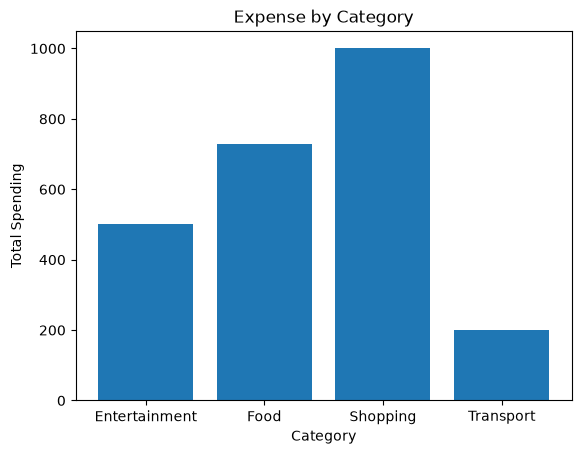

In [18]:
plt.bar(
    category_totals_df["category"],
    category_totals_df["amount"]
)

plt.xlabel("Category")
plt.ylabel("Total Spending")
plt.title("Expense by Category")

plt.show()

This:
```python
category_totals_df["category"]
```
provides the X-axis values.

This:
```python
category_totals_df["amount"]
```
provides the Y-axis values.

And:
```python
plt.bar(x, y)
```
creates the bars.

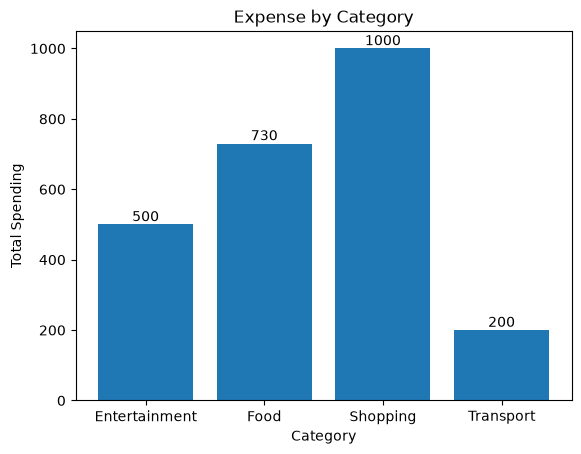

In [19]:
bars = plt.bar(
    category_totals_df["category"],
    category_totals_df["amount"]
)

plt.xlabel("Category")
plt.ylabel("Total Spending")
plt.title("Expense by Category")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.0f}",
        ha="center",
        va="bottom"
    )

plt.show()

In [20]:
category_totals_sorted = category_totals_df.sort_values(
    by="amount",
    ascending=False
)

category_totals_sorted

,category,amount
2,Shopping,1000
1,Food,730
0,Entertainment,500
3,Transport,200


In [21]:
category_totals_sorted.iloc[0]

category    Shopping
amount          1000
Name: 2, dtype: object

iloc means integer-location based selection.
```python
category_totals_sorted.iloc[0]
```
means: Give me the row at position 0.

Since we sorted descending, position 0 is the highest-spending category.

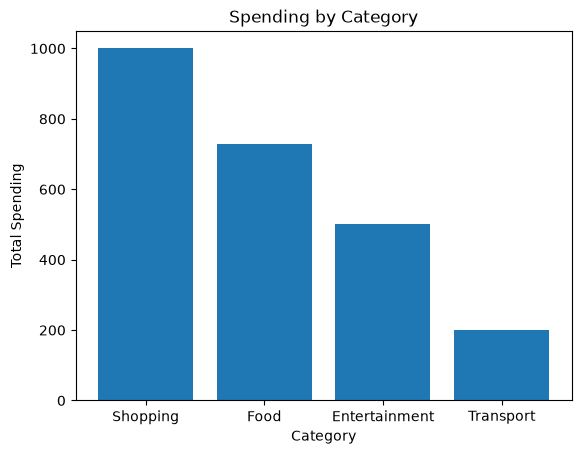

In [22]:
plt.bar(
    category_totals_sorted["category"],
    category_totals_sorted["amount"]
)

plt.xlabel("Category")
plt.ylabel("Total Spending")
plt.title("Spending by Category")

plt.show()

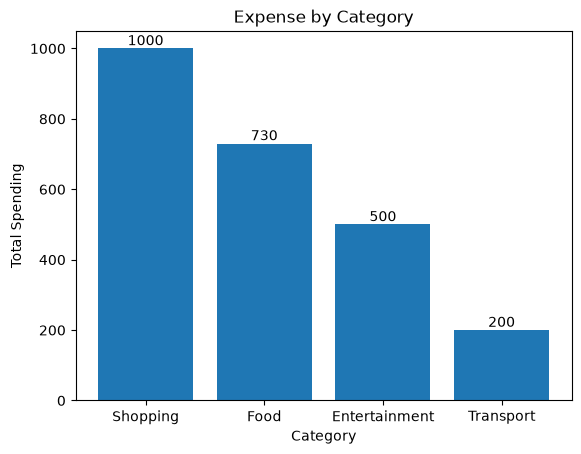

In [23]:
bars = plt.bar(
    category_totals_sorted["category"],
    category_totals_sorted["amount"]
)

plt.xlabel("Category")
plt.ylabel("Total Spending")
plt.title("Expense by Category")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.0f}",
        ha="center",
        va="bottom"
    )

plt.show()

In [24]:
avg = df["amount"].mean()
above_avg = df[df["amount"] > avg]

above_avg

,category,amount
3,Entertainment,500
5,Shopping,1000


In [25]:
df[(df["amount"] > 200) & (df["category"] == "Food")]

,category,amount
0,Food,250
2,Food,300


In [26]:
df[(df["category"] == "Food") | (df["category"] == "Transport")]

,category,amount
0,Food,250
1,Transport,120
2,Food,300
4,Transport,80
6,Food,180


In [27]:
df.sort_values(
    by = ["category", "amount"],
    ascending = [True, False]
)

,category,amount
3,Entertainment,500
2,Food,300
0,Food,250
6,Food,180
5,Shopping,1000
1,Transport,120
4,Transport,80


In [28]:
df.groupby("category")["amount"].mean()

category
Entertainment     500.000000
Food              243.333333
Shopping         1000.000000
Transport         100.000000
Name: amount, dtype: float64

This answers:
What's the average expense within each category?

In [29]:
df.groupby("category")["amount"].count()

category
Entertainment    1
Food             3
Shopping         1
Transport        2
Name: amount, dtype: int64

This answers:
How many expenses are recorded in each category?

In [30]:
df.groupby("category")["amount"].max()

category
Entertainment     500
Food              300
Shopping         1000
Transport         120
Name: amount, dtype: int64

This answers:
What's the highest expense within each category?

In [31]:
df.groupby("category")["amount"].min()

category
Entertainment     500
Food              180
Shopping         1000
Transport          80
Name: amount, dtype: int64

This answers:
What's the lowest expense within each category?

In [32]:
df.groupby("category")["amount"].agg(
    ["sum", "mean", "count", "max", "min"]
)

,sum,mean,count,max,min
category,,,,,
Entertainment,500,500.000000,1,500,500
Food,730,243.333333,3,300,180
Shopping,1000,1000.000000,1,1000,1000
Transport,200,100.000000,2,120,80


# Find the category that has the highest total spending.

**Beginer approch**

In [33]:
category_totals = df.groupby("category")["amount"].sum()

In [34]:
category_totals

category
Entertainment     500
Food              730
Shopping         1000
Transport         200
Name: amount, dtype: int64

In [35]:
category_totals_df = category_totals.reset_index()

In [36]:
category_totals_df

,category,amount
0,Entertainment,500
1,Food,730
2,Shopping,1000
3,Transport,200


In [37]:
category_totals_df.sort_values(
    by = "amount", ascending = False
).iloc[0]

category    Shopping
amount          1000
Name: 2, dtype: object

**Direct approch**

In [38]:
category_totals_df.loc[
    category_totals_df["amount"].idxmax()
]

category    Shopping
amount          1000
Name: 2, dtype: object

# One subtle distinction
iloc works by position, not by the DataFrame's index label.

For example:
```python
df.iloc[0]
```
means:
"Give me the first row."

Whereas:
```python
df.loc[0]
```
means:
"Give me the row whose index label is 0."

They often give the same result with a fresh DataFrame, which is why the distinction can be confusing.

# What is the average amount spent on Food?

**My version**

In [39]:
category_means_df = df.groupby("category")["amount"].mean().reset_index()

avg_food = category_means_df.loc[
    category_means_df["category"] == "Food"
]

avg_food

,category,amount
1,Food,243.333333


**Simpler version**

In [40]:
food_expenses = df[df["category"] == "Food"]

avg_food = food_expenses["amount"].mean()

avg_food

np.float64(243.33333333333334)

# Find the average expense for each category, then sort the categories from highest average expense to lowest.

In [41]:
category_means = df.groupby("category")["amount"].mean()
category_means

category
Entertainment     500.000000
Food              243.333333
Shopping         1000.000000
Transport         100.000000
Name: amount, dtype: float64

In [42]:
category_means_df = category_means.reset_index()
category_means_df

,category,amount
0,Entertainment,500.000000
1,Food,243.333333
2,Shopping,1000.000000
3,Transport,100.000000


In [43]:
category_means_df.sort_values(
    by = "amount",
    ascending = False
)

,category,amount
2,Shopping,1000.000000
0,Entertainment,500.000000
1,Food,243.333333
3,Transport,100.000000


In [44]:
category_stats = df.groupby("category")["amount"].agg(
    ["sum", "mean", "count", "max", "min"]
)

category_stats

,sum,mean,count,max,min
category,,,,,
Entertainment,500,500.000000,1,500,500
Food,730,243.333333,3,300,180
Shopping,1000,1000.000000,1,1000,1000
Transport,200,100.000000,2,120,80


# 📅 Date Time

In [45]:
expenses = [
    {"date": "2026-08-01", "category": "Food", "amount": 250},
    {"date": "2026-08-02", "category": "Transport", "amount": 120},
    {"date": "2026-08-03", "category": "Food", "amount": 300},
    {"date": "2026-08-05", "category": "Entertainment", "amount": 500},
    {"date": "2026-08-07", "category": "Transport", "amount": 80},
    {"date": "2026-08-10", "category": "Shopping", "amount": 1000},
    {"date": "2026-08-12", "category": "Food", "amount": 180},
]

In [46]:
df = pd.DataFrame(expenses)
df

,date,category,amount
0,2026-08-01,Food,250
1,2026-08-02,Transport,120
2,2026-08-03,Food,300
3,2026-08-05,Entertainment,500
4,2026-08-07,Transport,80
5,2026-08-10,Shopping,1000
6,2026-08-12,Food,180


In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   date      7 non-null      str  
 1   category  7 non-null      str  
 2   amount    7 non-null      int64
dtypes: int64(1), str(2)
memory usage: 300.0 bytes


In [48]:
df["date"] = pd.to_datetime(df["date"])

In [49]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      7 non-null      datetime64[us]
 1   category  7 non-null      str           
 2   amount    7 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 300.0 bytes


In [50]:
df["date"].dt.day

0     1
1     2
2     3
3     5
4     7
5    10
6    12
Name: date, dtype: int32

In [51]:
df["date"].dt.month

0    8
1    8
2    8
3    8
4    8
5    8
6    8
Name: date, dtype: int32

In [52]:
df["date"].dt.year

0    2026
1    2026
2    2026
3    2026
4    2026
5    2026
6    2026
Name: date, dtype: int32

In [53]:
df["date"].dt.day_name()

0     Saturday
1       Sunday
2       Monday
3    Wednesday
4       Friday
5       Monday
6    Wednesday
Name: date, dtype: str

In [54]:
df[df["date"] > "2026-08-05"]

,date,category,amount
4,2026-08-07,Transport,80
5,2026-08-10,Shopping,1000
6,2026-08-12,Food,180


In [55]:
df["date"].dt.weekday

0    5
1    6
2    0
3    2
4    4
5    0
6    2
Name: date, dtype: int32

In [56]:
df["day"] = df["date"].dt.day_name()
df

,date,category,amount,day
0,2026-08-01,Food,250,Saturday
1,2026-08-02,Transport,120,Sunday
2,2026-08-03,Food,300,Monday
3,2026-08-05,Entertainment,500,Wednesday
4,2026-08-07,Transport,80,Friday
5,2026-08-10,Shopping,1000,Monday
6,2026-08-12,Food,180,Wednesday


In [57]:
df["new"] = df["date"].dt.weekday
df

,date,category,amount,day,new
0,2026-08-01,Food,250,Saturday,5
1,2026-08-02,Transport,120,Sunday,6
2,2026-08-03,Food,300,Monday,0
3,2026-08-05,Entertainment,500,Wednesday,2
4,2026-08-07,Transport,80,Friday,4
5,2026-08-10,Shopping,1000,Monday,0
6,2026-08-12,Food,180,Wednesday,2


**Adding a new column**

In [58]:
df["quarter_name"] = "Q" + df["date"].dt.quarter.astype(str)

df[["date", "quarter_name"]]

,date,quarter_name
0,2026-08-01,Q3
1,2026-08-02,Q3
2,2026-08-03,Q3
3,2026-08-05,Q3
4,2026-08-07,Q3
5,2026-08-10,Q3
6,2026-08-12,Q3


Methods / functions → ()
-----------------------
```text
month_name()
day_name()
strftime()
```
Attributes
-----------------------
```text
year
month
day
hour
minute
second
```

In [59]:
df = df.drop(columns="new")
df

,date,category,amount,day,quarter_name
0,2026-08-01,Food,250,Saturday,Q3
1,2026-08-02,Transport,120,Sunday,Q3
2,2026-08-03,Food,300,Monday,Q3
3,2026-08-05,Entertainment,500,Wednesday,Q3
4,2026-08-07,Transport,80,Friday,Q3
5,2026-08-10,Shopping,1000,Monday,Q3
6,2026-08-12,Food,180,Wednesday,Q3


**Deleting a column**

In [60]:
df["double_amount"] = df["amount"] * 2

In [61]:
df

,date,category,amount,day,quarter_name,double_amount
0,2026-08-01,Food,250,Saturday,Q3,500
1,2026-08-02,Transport,120,Sunday,Q3,240
2,2026-08-03,Food,300,Monday,Q3,600
3,2026-08-05,Entertainment,500,Wednesday,Q3,1000
4,2026-08-07,Transport,80,Friday,Q3,160
5,2026-08-10,Shopping,1000,Monday,Q3,2000
6,2026-08-12,Food,180,Wednesday,Q3,360


In [62]:
days = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

In [63]:
df["day"] = pd.Categorical(
    df["day"],
    categories=days,
    ordered=True
)

In [64]:
df.groupby("day", observed=True)["amount"].sum().reset_index()

,day,amount
0,Monday,1300
1,Wednesday,680
2,Friday,80
3,Saturday,250
4,Sunday,120


In [65]:
df["month"] = df["date"].dt.month_name()
df

,date,category,amount,day,quarter_name,double_amount,month
0,2026-08-01,Food,250,Saturday,Q3,500,August
1,2026-08-02,Transport,120,Sunday,Q3,240,August
2,2026-08-03,Food,300,Monday,Q3,600,August
3,2026-08-05,Entertainment,500,Wednesday,Q3,1000,August
4,2026-08-07,Transport,80,Friday,Q3,160,August
5,2026-08-10,Shopping,1000,Monday,Q3,2000,August
6,2026-08-12,Food,180,Wednesday,Q3,360,August


In [66]:
expenses = [
    {"date": "2026-06-05", "category": "Food", "amount": 250},
    {"date": "2026-06-10", "category": "Transport", "amount": 120},
    {"date": "2026-06-15", "category": "Food", "amount": 300},
    {"date": "2026-07-02", "category": "Entertainment", "amount": 500},
    {"date": "2026-07-08", "category": "Transport", "amount": 80},
    {"date": "2026-07-20", "category": "Shopping", "amount": 1000},
    {"date": "2026-08-03", "category": "Food", "amount": 180},
    {"date": "2026-08-10", "category": "Transport", "amount": 200},
    {"date": "2026-08-15", "category": "Food", "amount": 350},
    {"date": "2026-08-20", "category": "Entertainment", "amount": 400},
]

In [67]:
df = pd.DataFrame(expenses)

df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.month_name()

df

,date,category,amount,month
0,2026-06-05,Food,250,June
1,2026-06-10,Transport,120,June
2,2026-06-15,Food,300,June
3,2026-07-02,Entertainment,500,July
4,2026-07-08,Transport,80,July
5,2026-07-20,Shopping,1000,July
6,2026-08-03,Food,180,August
7,2026-08-10,Transport,200,August
8,2026-08-15,Food,350,August
9,2026-08-20,Entertainment,400,August


In [68]:
monthly_spending = df.groupby("month")["amount"].sum()

monthly_spending

month
August    1130
July      1580
June       670
Name: amount, dtype: int64

In [69]:
months = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

In [70]:
df["month"] = pd.Categorical(
    df["month"],
    categories = months,
    ordered = True
)

In [71]:
df.groupby("month", observed=True)["amount"].sum().reset_index()

,month,amount
0,June,670
1,July,1580
2,August,1130


In [72]:
july_expenses = df[
    (df["date"] >= "2026-07-01") &
    (df["date"] <= "2026-07-31")
]

july_expenses

,date,category,amount,month
3,2026-07-02,Entertainment,500,July
4,2026-07-08,Transport,80,July
5,2026-07-20,Shopping,1000,July


In [73]:
df = df.set_index("date")

In [74]:
df

,category,amount,month
date,,,
2026-06-05,Food,250,June
2026-06-10,Transport,120,June
2026-06-15,Food,300,June
2026-07-02,Entertainment,500,July
2026-07-08,Transport,80,July
2026-07-20,Shopping,1000,July
2026-08-03,Food,180,August
2026-08-10,Transport,200,August
2026-08-15,Food,350,August


In [75]:
df.loc["2026-07"]

,category,amount,month
date,,,
2026-07-02,Entertainment,500,July
2026-07-08,Transport,80,July
2026-07-20,Shopping,1000,July


In [76]:
monthly_Total = df["amount"].resample("ME").sum()

monthly_Total.reset_index()

,date,amount
0,2026-06-30,670
1,2026-07-31,1580
2,2026-08-31,1130


In [77]:
monthly_avg = df["amount"].resample("ME").mean()

monthly_avg.reset_index()

,date,amount
0,2026-06-30,223.333333
1,2026-07-31,526.666667
2,2026-08-31,282.500000


In [78]:
monthly_expense_no = df["amount"].resample("ME").count()

monthly_expense_no.reset_index()

,date,amount
0,2026-06-30,3
1,2026-07-31,3
2,2026-08-31,4


In [79]:
monthly_category_spending = (
    df.groupby(
        [df.index.to_period("M"), "category"],
        observed=True
    )["amount"]
    .sum()
)

monthly_category_spending

date     category     
2026-06  Food              550
         Transport         120
2026-07  Entertainment     500
         Shopping         1000
         Transport          80
2026-08  Entertainment     400
         Food              530
         Transport         200
Name: amount, dtype: int64

In [80]:
monthly_category_spending.reset_index()

,date,category,amount
0,2026-06,Food,550
1,2026-06,Transport,120
2,2026-07,Entertainment,500
3,2026-07,Shopping,1000
4,2026-07,Transport,80
5,2026-08,Entertainment,400
6,2026-08,Food,530
7,2026-08,Transport,200


In [81]:
monthly_expense_report = df["amount"].resample("ME").agg(
    ["sum", "mean", "count"]
).reset_index()

monthly_expense_report

,date,sum,mean,count
0,2026-06-30,670,223.333333,3
1,2026-07-31,1580,526.666667,3
2,2026-08-31,1130,282.500000,4


In [82]:
monthly_expense_report = monthly_expense_report.rename(
    columns = {
        "sum": "total",
        "mean": "average",
        "count": "number_of_expenses"
    }
)

monthly_expense_report

,date,total,average,number_of_expenses
0,2026-06-30,670,223.333333,3
1,2026-07-31,1580,526.666667,3
2,2026-08-31,1130,282.500000,4


In [83]:
monthly_expense_report["date"] = (
    monthly_expense_report["date"].dt.to_period("M")
)

monthly_expense_report

,date,total,average,number_of_expenses
0,2026-06,670,223.333333,3
1,2026-07,1580,526.666667,3
2,2026-08,1130,282.500000,4


## Data Cleaning

In [84]:
expenses = [
    {"date": "2026-08-01", "category": "Food", "amount": 250},
    {"date": "2026-08-02", "category": "Transport", "amount": 120},
    {"date": "2026-08-03", "category": "Food", "amount": None},
    {"date": "2026-08-05", "category": "Entertainment", "amount": 500},
    {"date": "2026-08-05", "category": "Entertainment", "amount": 500},
    {"date": "2026-08-07", "category": None, "amount": 80},
    {"date": "2026-08-10", "category": "Shopping", "amount": 1000},
    {"date": "2026-08-12", "category": "Food", "amount": 180},
]

df = pd.DataFrame(expenses)

df

,date,category,amount
0,2026-08-01,Food,250.0
1,2026-08-02,Transport,120.0
2,2026-08-03,Food,NaN
3,2026-08-05,Entertainment,500.0
4,2026-08-05,Entertainment,500.0
5,2026-08-07,NaN,80.0
6,2026-08-10,Shopping,1000.0
7,2026-08-12,Food,180.0


In [85]:
df.isna()

,date,category,amount
0,False,False,False
1,False,False,False
2,False,False,True
3,False,False,False
4,False,False,False
5,False,True,False
6,False,False,False
7,False,False,False


In [86]:
df.isna().sum()

date        0
category    1
amount      1
dtype: int64

This means: "Count how many missing values are in each column."

In [87]:
df[df.isna().any(axis = 1)]

,date,category,amount
2,2026-08-03,Food,NaN
5,2026-08-07,NaN,80.0


```python
.any(axis=1)
```
This asks: "Does this row contain at least one True?"

axis=1 → work across columns → evaluate each ROW
axis=0 → work down rows → evaluate each COLUMN

```python
df.isna().any(axis=1)
```
means: Find rows where at least one value is missing.

In [88]:
df["category"].fillna("Unknown")

0             Food
1        Transport
2             Food
3    Entertainment
4    Entertainment
5          Unknown
6         Shopping
7             Food
Name: category, dtype: str

* It replaces the NaN with Unknown at row 5 category but does not change the main dataset or df

In [89]:
df["category"] = df["category"].fillna("Unknown")

In [90]:
df

,date,category,amount
0,2026-08-01,Food,250.0
1,2026-08-02,Transport,120.0
2,2026-08-03,Food,NaN
3,2026-08-05,Entertainment,500.0
4,2026-08-05,Entertainment,500.0
5,2026-08-07,Unknown,80.0
6,2026-08-10,Shopping,1000.0
7,2026-08-12,Food,180.0


* Now this changes the df directly

In [91]:
df = df.dropna(subset=["amount"])

In [92]:
df

,date,category,amount
0,2026-08-01,Food,250.0
1,2026-08-02,Transport,120.0
3,2026-08-05,Entertainment,500.0
4,2026-08-05,Entertainment,500.0
5,2026-08-07,Unknown,80.0
6,2026-08-10,Shopping,1000.0
7,2026-08-12,Food,180.0


* This delete the row who's amount is missing, means row 2

```python
subset=["amount"]
```
It means: "Only consider the amount column when deciding which rows to remove."

In [93]:
df.isna().sum()

date        0
category    0
amount      0
dtype: int64

In [94]:
df.duplicated()

0    False
1    False
3    False
4     True
5    False
6    False
7    False
dtype: bool

In [95]:
df.duplicated().sum()

np.int64(1)

In [96]:
df = df.drop_duplicates()

df

,date,category,amount
0,2026-08-01,Food,250.0
1,2026-08-02,Transport,120.0
3,2026-08-05,Entertainment,500.0
5,2026-08-07,Unknown,80.0
6,2026-08-10,Shopping,1000.0
7,2026-08-12,Food,180.0


In [97]:
df = df.reset_index(drop=True)

df

,date,category,amount
0,2026-08-01,Food,250.0
1,2026-08-02,Transport,120.0
2,2026-08-05,Entertainment,500.0
3,2026-08-07,Unknown,80.0
4,2026-08-10,Shopping,1000.0
5,2026-08-12,Food,180.0


## Why drop=True?

Without it:
```python
df.reset_index()
```
Pandas would preserve the old index as a new column.

With:
```python
df.reset_index(drop=True)
```
we're saying: "Throw away the old index and create a fresh one."

In [98]:
df.duplicated().sum()

np.int64(0)

In [99]:
df.dtypes

date            str
category        str
amount      float64
dtype: object

In [100]:
df["date"] = pd.to_datetime(df["date"])

In [101]:
df.dtypes

date        datetime64[us]
category               str
amount             float64
dtype: object

In [102]:
df[df["amount"] < 0]

,date,category,amount


In [103]:
(df["amount"] < 0).sum()

np.int64(0)

In [104]:
test_df = df.copy()

test_df.loc[len(test_df)] = {
    "date": pd.Timestamp("2026-08-20"),
    "category": "Food",
    "amount": -500
}

In [105]:
test_df

,date,category,amount
0,2026-08-01,Food,250.0
1,2026-08-02,Transport,120.0
2,2026-08-05,Entertainment,500.0
3,2026-08-07,Unknown,80.0
4,2026-08-10,Shopping,1000.0
5,2026-08-12,Food,180.0
6,2026-08-20,Food,-500.0


In [106]:
test_df[test_df["amount"] < 0]

,date,category,amount
6,2026-08-20,Food,-500.0


In [107]:
(test_df["amount"] < 0).sum()

np.int64(1)

In [108]:
test_df = test_df[test_df["amount"] >= 0]

test_df

,date,category,amount
0,2026-08-01,Food,250.0
1,2026-08-02,Transport,120.0
2,2026-08-05,Entertainment,500.0
3,2026-08-07,Unknown,80.0
4,2026-08-10,Shopping,1000.0
5,2026-08-12,Food,180.0


# So your data cleaning toolkit so far is:

## Find missing values
```python
df.isna().sum()
```
## Remove rows with missing values
```python
df.dropna(subset=["amount"])
```
## Fill missing values
```python
df["category"] = df["category"].fillna("Unknown")
```
## Find duplicates
```python
df.duplicated()
```
## Remove duplicates
```python
df.drop_duplicates()
```
## Remove negative amounts
```python
df = df[df["amount"] >= 0]
```

In [109]:
df["category"].unique()

<StringArray>
['Food', 'Transport', 'Entertainment', 'Unknown', 'Shopping']
Length: 5, dtype: str

This gives us every different category currently present.

In [110]:
test_df = df.copy()

test_df.loc[len(test_df)] = {
    "date": pd.Timestamp("2026-08-22"),
    "category": "food",
    "amount": 300
}

test_df

,date,category,amount
0,2026-08-01,Food,250.0
1,2026-08-02,Transport,120.0
2,2026-08-05,Entertainment,500.0
3,2026-08-07,Unknown,80.0
4,2026-08-10,Shopping,1000.0
5,2026-08-12,Food,180.0
6,2026-08-22,food,300.0


In [111]:
test_df["category"].unique()

<StringArray>
['Food', 'Transport', 'Entertainment', 'Unknown', 'Shopping', 'food']
Length: 6, dtype: str

In [112]:
test_df["category"] = test_df["category"].str.lower()

In [113]:
test_df["category"].unique()

<StringArray>
['food', 'transport', 'entertainment', 'unknown', 'shopping']
Length: 5, dtype: str

In [114]:
test_df["category"] = test_df["category"].str.capitalize()

In [115]:
test_df

,date,category,amount
0,2026-08-01,Food,250.0
1,2026-08-02,Transport,120.0
2,2026-08-05,Entertainment,500.0
3,2026-08-07,Unknown,80.0
4,2026-08-10,Shopping,1000.0
5,2026-08-12,Food,180.0
6,2026-08-22,Food,300.0


* .str.lower() → everything becomes lowercase
* .str.upper() → everything becomes uppercase
* .str.capitalize() → first character uppercase, rest lowercase
* .str.title() → first character of each word uppercase

In [116]:
test_df.loc[len(test_df)] = {
    "date": pd.Timestamp("2026-08-23"),
    "category": " Food ",
    "amount": 200
}

In [117]:
test_df["category"].unique()

<StringArray>
['Food', 'Transport', 'Entertainment', 'Unknown', 'Shopping', ' Food ']
Length: 6, dtype: str

In [118]:
test_df["category"] = test_df["category"].str.strip().str.capitalize()

In [119]:
test_df["category"].unique()

<StringArray>
['Food', 'Transport', 'Entertainment', 'Unknown', 'Shopping']
Length: 5, dtype: str

In [120]:
test_df

,date,category,amount
0,2026-08-01,Food,250.0
1,2026-08-02,Transport,120.0
2,2026-08-05,Entertainment,500.0
3,2026-08-07,Unknown,80.0
4,2026-08-10,Shopping,1000.0
5,2026-08-12,Food,180.0
6,2026-08-22,Food,300.0
7,2026-08-23,Food,200.0


In [121]:
test_df.loc[len(test_df)] = {
    "date": pd.Timestamp("2026-08-24"),
    "category": "Travel",
    "amount": 700
}

test_df.loc[len(test_df)] = {
    "date": pd.Timestamp("2026-08-25"),
    "category": "Bills",
    "amount": 400
}

In [122]:
test_df["category"].unique()

<StringArray>
['Food', 'Transport', 'Entertainment', 'Unknown', 'Shopping', 'Travel',
 'Bills']
Length: 7, dtype: str

In [123]:
valid_categories = [
    "Food",
    "Transport",
    "Entertainment",
    "Unknown",
    "Shopping"
]

In [124]:
test_df["category"].isin(valid_categories)

0     True
1     True
2     True
3     True
4     True
5     True
6     True
7     True
8    False
9    False
Name: category, dtype: bool

* True → valid category
* False → invalid category

In [125]:
test_df[test_df["category"].isin(valid_categories) == False]

,date,category,amount
8,2026-08-24,Travel,700.0
9,2026-08-25,Bills,400.0


In [126]:
test_df[~test_df["category"].isin(valid_categories)]

,date,category,amount
8,2026-08-24,Travel,700.0
9,2026-08-25,Bills,400.0


### So:
```python
test_df["category"].isin(valid_categories)
```
means: "Is this category valid?"

### while:
```python
~test_df["category"].isin(valid_categories)
```
means: "Is this category not valid?"

In [127]:
test_df.loc[~test_df["category"].isin(valid_categories), "category"] = "Unknown"

```python
.loc[condition, "category"]
```

In [128]:
test_df

,date,category,amount
0,2026-08-01,Food,250.0
1,2026-08-02,Transport,120.0
2,2026-08-05,Entertainment,500.0
3,2026-08-07,Unknown,80.0
4,2026-08-10,Shopping,1000.0
5,2026-08-12,Food,180.0
6,2026-08-22,Food,300.0
7,2026-08-23,Food,200.0
8,2026-08-24,Unknown,700.0
9,2026-08-25,Unknown,400.0


In [129]:
test_df["category"].unique()

<StringArray>
['Food', 'Transport', 'Entertainment', 'Unknown', 'Shopping']
Length: 5, dtype: str

In [130]:
test_df["amount"].describe()

count      10.000000
mean      373.000000
std       289.522596
min        80.000000
25%       185.000000
50%       275.000000
75%       475.000000
max      1000.000000
Name: amount, dtype: float64

* Median = ₹275
* Maximum = ₹1000
* ₹1000 ÷ ₹275 ≈ 3.64×
```text
So ₹1000 is much larger than the typical expense.

But here's an important data-analysis lesson: Being an outlier doesn't necessarily mean being an error.

For example, if you bought a ₹1000 pair of shoes, that's a legitimate expense. We might flag it for inspection rather than automatically delete it.
```
### A common method is the IQR (Interquartile Range).
Remember:
Q1 = 25th percentile
Q3 = 75th percentile
IQR = Q3 − Q1

In [131]:
q1 = test_df["amount"].quantile(0.25)
q3 = test_df["amount"].quantile(0.75)

print(f"25th percentile = {q1}")
print(f"75th percentile = {q3}")

25th percentile = 185.0
75th percentile = 475.0


In [132]:
iqr = q3 - q1

print("The IQR =", iqr)

The IQR = 290.0


In [133]:
upper_bound = q3 + 1.5 * iqr
lower_bound = q1 - 1.5 * iqr

print(f"The upper bound is = {upper_bound}")
print(f"The lower bound is = {lower_bound}")

The upper bound is = 910.0
The lower bound is = -250.0


1.5 is not a magical property of the data—it's a conventional threshold used in the IQR outlier rule, often called the 1.5 × IQR rule.

### Why multiply by 1.5?

The IQR tells us how spread out the middle 50% of our data is.

For your data:

Q1 = ₹185
Q3 = ₹475

IQR = ₹475 - ₹185
    = ₹290

We then say: An observation is unusually far away if it is more than 1.5 IQRs beyond Q1 or Q3.

So:

Upper Bound = Q3 + 1.5 × IQR
            = 475 + 1.5 × 290

The 1.5 controls how far away from the middle 50% a value must be before we flag it.

Why specifically 1.5?

It's a statistical convention, not a law of nature. It was popularized by statistician John Tukey as part of the boxplot method.

Think of it like a tolerance zone:

        Normal middle data
              ↓
     Q1 ───────────── Q3
    ₹185             ₹475
      |<---- IQR ---->|

                        ← 1.5 × IQR →
                                |
                           Upper bound

If we used:

1 × IQR → we'd flag more values
1.5 × IQR → standard/common choice
3 × IQR → we'd flag only very extreme values

So 1.5 is a chosen threshold that provides a practical balance between being too sensitive and too lenient.

And importantly, an IQR outlier is a potential outlier, not automatically a bad data point.

In [134]:
test_df[(test_df["amount"] < lower_bound) | (test_df["amount"] > upper_bound)]

,date,category,amount
4,2026-08-10,Shopping,1000.0


In [135]:
test_df["is_outlier"] = (
    (test_df["amount"] < lower_bound) |
    (test_df["amount"] > upper_bound)
)

In [136]:
test_df[test_df["is_outlier"]]

,date,category,amount,is_outlier
4,2026-08-10,Shopping,1000.0,True


# 🚀 Lesson: Pandas apply()

Suppose we have:

In [137]:
import pandas as pd

df = pd.DataFrame({
    "category": ["Food", "Transport", "Shopping", "Food"],
    "amount": [250, 120, 1000, 500]
})

df

,category,amount
0,Food,250
1,Transport,120
2,Shopping,1000
3,Food,500


## 🎯 Your first challenge

Write your own function called:
```python
def expense_type(amount):
    ...
```
```text
Rules:

< 300 → "Small"
300–700 → "Medium"
> 700 → "Large"
```

In [138]:
def expense_type(amount):
    if amount < 300:
        return "Small"
    elif amount > 700:
        return "Large"
    else:
        return "Medium"

In [139]:
df["amount"].apply(expense_type)

0     Small
1     Small
2     Large
3    Medium
Name: amount, dtype: str

In [140]:
df["expense_type"] = df["amount"].apply(expense_type)

In [141]:
df

,category,amount,expense_type
0,Food,250,Small
1,Transport,120,Small
2,Shopping,1000,Large
3,Food,500,Medium


# 🧠 Challenge 2 — Apply to text

Now let's use apply() on a text column.

Write a function:
```python
def clean_category(category):
    ...
```
```text
It should: Remove spaces from the beginning/end.
Make the first letter uppercase and the rest lowercase.

For example:

" food "       → "Food"
"TRANSPORT"    → "Transport"
" Shopping "   → "Shopping"

Hint: You already learned both string methods needed for this. 😉
```

In [142]:
df = pd.DataFrame({
    "category": [
        " food ",
        "TRANSPORT",
        " Shopping ",
        "entertainment",
        " Food",
        "transport "
    ],
    "amount": [250, 120, 1000, 500, 300, 80]
})

df

,category,amount
0,food,250
1,TRANSPORT,120
2,Shopping,1000
3,entertainment,500
4,Food,300
5,transport,80


In [143]:
def clean_category(category):
    return category.strip().capitalize()

You correctly noticed an important distinction:
```python
category.strip().capitalize()
```
inside a normal Python function, versus:
```python
df["category"].str.strip().str.capitalize()
```

In [144]:
df["category"] = df["category"].apply(clean_category)

In [145]:
df

,category,amount
0,Food,250
1,Transport,120
2,Shopping,1000
3,Entertainment,500
4,Food,300
5,Transport,80


# 🚀 Challenge 3 — A more useful transformation

Let's add a new column based on the amount.

Create this function:
```python
def spending_level(amount):
    ...
```
```text
Rules:

< 200 → "Low"
200–500 → "Medium"
> 500 → "High"
```

In [146]:
def spending_level(amount):
    if amount < 200:
        return "Low"
    elif amount > 500:
        return "High"
    else:
        return "Medium"

In [147]:
df["spending_level"] = df["amount"].apply(spending_level)

In [148]:
df

,category,amount,spending_level
0,Food,250,Medium
1,Transport,120,Low
2,Shopping,1000,High
3,Entertainment,500,Medium
4,Food,300,Medium
5,Transport,80,Low


# 🚀Let's create a function that uses multiple pieces of information from the same row.
Suppose we want to label an expense as "Important" when:
* category is "Food" and
* amount is greater than ₹260
* Otherwise → "Normal".

Now the function needs both category and amount.

This is where df.apply(..., axis=1) becomes useful.

## 🎯 Your challenge
Write:
```python
def expense_priority(row):
    ...
```
```text
Rules:
If category is "Food" AND amount > 260 → "Important"
Otherwise → "Normal"
```

In [149]:
def expense_priority(row):
    if row["category"] == "Food" and row["amount"] > 260:
        return "Important"
    else:
        return "normal"

In [150]:
df["priority"] = df.apply(expense_priority, axis=1)

In [151]:
df

,category,amount,spending_level,priority
0,Food,250,Medium,normal
1,Transport,120,Low,normal
2,Shopping,1000,High,normal
3,Entertainment,500,Medium,normal
4,Food,300,Medium,Important
5,Transport,80,Low,normal


# 🎯 Your challenge

Let's practice something simple first.

Using your df, create a new column called "amount_with_tax" where 10% tax is added to every expense.

You need to complete:
```python
df["amount_with_tax"] = df["amount"].apply(
    lambda x: __________________
)
```
```text
For example:

₹100 → ₹110
₹200 → ₹220
```

In [152]:
df["amount_with_tax"] = df["amount"].apply(
    lambda x: x * 1.10
)

In [153]:
df

,category,amount,spending_level,priority,amount_with_tax
0,Food,250,Medium,normal,275.0
1,Transport,120,Low,normal,132.0
2,Shopping,1000,High,normal,1100.0
3,Entertainment,500,Medium,normal,550.0
4,Food,300,Medium,Important,330.0
5,Transport,80,Low,normal,88.0


# 🚀 Challenge: Lambda + condition
```text
Let's make it slightly harder.

Create a column called "expense_status":
amount >= ₹500 → "High"
amount < ₹500 → "Normal"

Use lambda, not def.
```

In [154]:
df["expense_status"] = df["amount"].apply(
    lambda x: "High" if x >= 500 else "Normal"
)

df

,category,amount,spending_level,priority,amount_with_tax,expense_status
0,Food,250,Medium,normal,275.0,Normal
1,Transport,120,Low,normal,132.0,Normal
2,Shopping,1000,High,normal,1100.0,High
3,Entertainment,500,Medium,normal,550.0,High
4,Food,300,Medium,Important,330.0,Normal
5,Transport,80,Low,normal,88.0,Normal


# Create a column called "discounted_amount" where:

If amount >= ₹500 → give 10% discount
Otherwise → no discount

In [155]:
df["discounted_amount"] = df["amount"].apply(
    lambda x: x * 0.9 if x >= 500 else x
)

df

,category,amount,spending_level,priority,amount_with_tax,expense_status,discounted_amount
0,Food,250,Medium,normal,275.0,Normal,250.0
1,Transport,120,Low,normal,132.0,Normal,120.0
2,Shopping,1000,High,normal,1100.0,High,900.0
3,Entertainment,500,Medium,normal,550.0,High,450.0
4,Food,300,Medium,Important,330.0,Normal,300.0
5,Transport,80,Low,normal,88.0,Normal,80.0


# 🔗 Combining DataFrames
```text
There are two important tools:

concat() → stack DataFrames together
merge() → join DataFrames using a common column

We'll learn concat() first because it's simpler.

1. concat() — putting DataFrames together

Imagine we have expenses from two different weeks.
```

In [156]:
week1 = pd.DataFrame({
    "date": ["2026-08-01", "2026-08-02", "2026-08-03"],
    "category": ["Food", "Transport", "Shopping"],
    "amount": [250, 120, 1000]
})

week1

,date,category,amount
0,2026-08-01,Food,250
1,2026-08-02,Transport,120
2,2026-08-03,Shopping,1000


In [157]:
week2 = pd.DataFrame({
    "date": ["2026-08-04", "2026-08-05", "2026-08-06"],
    "category": ["Food", "Entertainment", "Transport"],
    "amount": [300, 500, 80]
})

week2

,date,category,amount
0,2026-08-04,Food,300
1,2026-08-05,Entertainment,500
2,2026-08-06,Transport,80


In [158]:
all_expenses = pd.concat([week1, week2])

In [159]:
all_expenses

,date,category,amount
0,2026-08-01,Food,250
1,2026-08-02,Transport,120
2,2026-08-03,Shopping,1000
0,2026-08-04,Food,300
1,2026-08-05,Entertainment,500
2,2026-08-06,Transport,80


In [160]:
all_expenses = pd.concat([week1, week2], ignore_index = True)

all_expenses

,date,category,amount
0,2026-08-01,Food,250
1,2026-08-02,Transport,120
2,2026-08-03,Shopping,1000
3,2026-08-04,Food,300
4,2026-08-05,Entertainment,500
5,2026-08-06,Transport,80


## 🎯 Your first challenge

Create these two DataFrames yourself:
```python
jan = pd.DataFrame({
    "category": ["Food", "Shopping"],
    "amount": [200, 500]
})

feb = pd.DataFrame({
    "category": ["Transport", "Food"],
    "amount": [100, 300]
})
```
Then combine them into:

expenses = __________________

In [161]:
jan = pd.DataFrame({
    "category": ["Food", "Shopping"],
    "amount": [200, 500]
})

feb = pd.DataFrame({
    "category": ["Transport", "Food"],
    "amount": [100, 300]
})

In [162]:
expenses = pd.concat([jan, feb], ignore_index =True)

In [163]:
expenses

,category,amount
0,Food,200
1,Shopping,500
2,Transport,100
3,Food,300


In [164]:
jan = pd.DataFrame({
    "category": ["Food", "Shopping"],
    "amount": [200, 500]
})

feb = pd.DataFrame({
    "category": ["Transport", "Food"],
    "amount": [100, 300],
    "payment_method": ["Cash", "UPI"]
})

expenses = pd.concat([jan, feb], ignore_index=True)

expenses

,category,amount,payment_method
0,Food,200,NaN
1,Shopping,500,NaN
2,Transport,100,Cash
3,Food,300,UPI


* Since January doesn't have payment_method, Pandas has no value to put there, so it uses NaN.

# Now let's learn merge() 🔗

Imagine we have:

Expenses:
```python
expenses = pd.DataFrame({
    "category": ["Food", "Shopping", "Transport"],
    "amount": [200, 500, 100]
})
```
Category information:
```python
category_info = pd.DataFrame({
    "category": ["Food", "Shopping", "Transport"],
    "budget": [5000, 3000, 2000]
})
```
Both DataFrames have a common column: "category"

We can use that column to connect the datasets:

In [165]:
# Expenses:

expenses = pd.DataFrame({
    "category": ["Food", "Shopping", "Transport"],
    "amount": [200, 500, 100]
})

In [166]:
# Category information:

category_info = pd.DataFrame({
    "category": ["Food", "Shopping", "Transport"],
    "budget": [5000, 3000, 2000]
})

In [167]:
result = pd.merge(
    expenses,
    category_info,
    on="category"
)

In [168]:
result

,category,amount,budget
0,Food,200,5000
1,Shopping,500,3000
2,Transport,100,2000


The key difference

concat()

"Put these datasets together."

merge()

"Match these datasets using a common column."

Think of merge() like a database JOIN.

In [169]:
students = pd.DataFrame({
    "student_id": [101, 102, 103],
    "name": ["Rahul", "Amit", "Priya"]
})

marks = pd.DataFrame({
    "student_id": [101, 102, 103],
    "marks": [85, 72, 91]
})

In [170]:
result = pd.merge(
    students,
    marks,
    on="student_id"
)

result

,student_id,name,marks
0,101,Rahul,85
1,102,Amit,72
2,103,Priya,91


## 🔥 merge() becomes interesting when IDs don't match

Let's add a student who doesn't have marks yet:
```python
students = pd.DataFrame({
    "student_id": [101, 102, 103, 104],
    "name": ["Rahul", "Amit", "Priya", "Rohan"]
})

marks = pd.DataFrame({
    "student_id": [101, 102, 103],
    "marks": [85, 72, 91]
})
```
```text
Now notice:

students → 101, 102, 103, 104
marks    → 101, 102, 103

Student 104 doesn't exist in marks.

If you run:
```
```python
pd.merge(students, marks, on="student_id")
```
```text
what do you think happens to Rohan (104)?

A. Rohan appears with NaN for marks

B. Rohan disappears

C. Pandas gives an error

Answer: B
```
```text
By default, pd.merge() performs an inner join.
```
```python
pd.merge(students, marks, on="student_id")
```
means: Keep only the rows where student_id exists in both DataFrames.

So:
```table
students       marks
101  ✓         101  ✓
102  ✓         102  ✓
103  ✓         103  ✓
104  ✓         ❌
```
Student 104 has no matching row in marks, so Rohan disappears.

## 🔗 How do we keep Rohan?

* That's where how= comes in.
```python
pd.merge(
    students,
    marks,
    on="student_id",
    how="left"
)
```

In [171]:
students = pd.DataFrame({
    "student_id": [101, 102, 103, 104],
    "name": ["Rahul", "Amit", "Priya", "Rohan"]
})

marks = pd.DataFrame({
    "student_id": [101, 102, 103],
    "marks": [85, 72, 91]
})

In [172]:
result = pd.merge(
    students,
    marks,
    on="student_id",
    how="left"
)

result

,student_id,name,marks
0,101,Rahul,85.0
1,102,Amit,72.0
2,103,Priya,91.0
3,104,Rohan,NaN


A left join means: Keep everything from the left DataFrame, even if there's no match on the right.

So we'd get:

|    |  student_id | name  | marks|
| :--- | :--- | :--- |:--- |
|0   |     101     | Rahul | 85.0 |
|1   |     102     | Amit  | 72.0 |
|2   |     103     | Priya | 91.0 |
|3   |     104     | Rohan |  NaN |

Rohan stays, but his marks are NaN because there is no matching value.

## 🧠 Remember these four:
|how    |	Meaning|
| :--- | :--- |
|"inner"|Only matching rows |
|"left"|	Everything from left + matches|
|"right" |	Everything from right + matches|
|"outer"|	Everything from both|

In [173]:
students = pd.DataFrame({
    "student_id": [101, 102, 103, 104],
    "name": ["Rahul", "Amit", "Priya", "Rohan"]
})

marks = pd.DataFrame({
    "student_id": [101, 102, 103],
    "marks": [85, 72, 91]
})

In [174]:
students = pd.DataFrame({
    "student_id": [101, 102, 103],
    "name": ["Rahul", "Amit", "Priya"]
})

marks = pd.DataFrame({
    "id": [101, 102, 103],
    "marks": [85, 72, 91]
})

In [175]:
result = pd.merge(
    students,
    marks,
    left_on="student_id",
    right_on="id",
)

result

,student_id,name,id,marks
0,101,Rahul,101,85
1,102,Amit,102,72
2,103,Priya,103,91


## 🧠 Remember

When the key names are the same:
```python
on="student_id"
```
When the key names are different:
```python
left_on="student_id"
right_on="id"
```

## 🎯 Your challenge

Use these:
```python
employees = pd.DataFrame({
    "employee_id": [1, 2, 3],
    "name": ["Rohan", "Amit", "Priya"]
})

salaries = pd.DataFrame({
    "emp_id": [1, 2, 3],
    "salary": [30000, 40000, 35000]
})
```
Merge them so the result contains each employee's salary.

In [176]:
employees = pd.DataFrame({
    "employee_id": [1, 2, 3],
    "name": ["Rohan", "Amit", "Priya"]
})

salaries = pd.DataFrame({
    "emp_id": [1, 2, 3],
    "salary": [30000, 40000, 35000]
})

In [177]:
result = pd.merge(
    employees,
    salaries,
    left_on="employee_id",
    right_on="emp_id"
)

result

,employee_id,name,emp_id,salary
0,1,Rohan,1,30000
1,2,Amit,2,40000
2,3,Priya,3,35000


# 🚀 Final merge() challenge

Let's make this more realistic.
```python
employees = pd.DataFrame({
    "employee_id": [1, 2, 3, 4],
    "name": ["Rohan", "Amit", "Priya", "Sneha"]
})

salaries = pd.DataFrame({
    "emp_id": [1, 2, 3],
    "salary": [30000, 40000, 35000]
})
```
```text
Notice:
employees → 1, 2, 3, 4
salaries  → 1, 2, 3

Sneha (4) doesn't have a salary record.
```
## 🎯 Your task
```text
Create a merged DataFrame that:

Keeps every employee, even if they don't have a salary.

You'll need:
```
* left_on
* right_on
* how

In [178]:
employees = pd.DataFrame({
    "employee_id": [1, 2, 3, 4],
    "name": ["Rohan", "Amit", "Priya", "Sneha"]
})

salaries = pd.DataFrame({
    "emp_id": [1, 2, 3],
    "salary": [30000, 40000, 35000]
})

In [179]:
result = pd.merge(
    employees,
    salaries,
    left_on="employee_id",
    right_on="emp_id",
    how="left"
).drop(columns="emp_id")

result

,employee_id,name,salary
0,1,Rohan,30000.0
1,2,Amit,40000.0
2,3,Priya,35000.0
3,4,Sneha,NaN


In [180]:
import pandas as pd

df = pd.DataFrame({
    "category": ["Food", "Food", "Transport", "Transport", "Shopping", "Shopping"],
    "month": ["June", "July", "June", "July", "June", "July"],
    "amount": [300, 500, 150, 200, 700, 400]
})

df

,category,month,amount
0,Food,June,300
1,Food,July,500
2,Transport,June,150
3,Transport,July,200
4,Shopping,June,700
5,Shopping,July,400


In [181]:
df.pivot_table(
    index="category",
    columns="month",
    values="amount"
)

month,July,June
category,,
Food,500.0,300.0
Shopping,400.0,700.0
Transport,200.0,150.0


## 🧠 What each part means
```python
index="category"
```
➡️ What should become the rows?
```python
columns="month"
```
➡️ What should become the columns?
```python
values="amount"
```
➡️ What values should fill the table?

So think:
```python
pivot_table()
```
* index   → rows
* columns → columns
* values  → data inside the table

## 🧠 One important thing

pivot_table() is especially useful when you have repeated combinations.

For example, suppose Food appears twice in June:
```text
Food | June | 300
Food | June | 200
```
A normal pivot() would have a problem because there are two values for:

Food + June

But pivot_table() can aggregate them.

By default, it uses the mean:
```python
df.pivot_table(
    index="category",
    columns="month",
    values="amount",
    aggfunc="mean"
)
```
We can also use:
```python
aggfunc="sum"
```
to get the total.

In [182]:
df = pd.DataFrame({
    "category": [
        "Food", "Food", "Food",
        "Transport", "Transport",
        "Shopping", "Shopping"
    ],
    "month": [
        "June", "June", "July",
        "June", "July",
        "June", "July"
    ],
    "amount": [
        300, 200, 500,
        150, 200,
        700, 400
    ]
})

df

,category,month,amount
0,Food,June,300
1,Food,June,200
2,Food,July,500
3,Transport,June,150
4,Transport,July,200
5,Shopping,June,700
6,Shopping,July,400


In [183]:
df.pivot_table(
    index="category",
    columns="month",
    values="amount",
    aggfunc="sum"
)

month,July,June
category,,
Food,500,500
Shopping,400,700
Transport,200,150


# 🎯 Challenge: two values

Now let's make the DataFrame slightly richer:
```python
df = pd.DataFrame({
    "category": ["Food", "Food", "Transport", "Transport", "Shopping", "Shopping"],
    "month": ["June", "July", "June", "July", "June", "July"],
    "amount": [300, 500, 150, 200, 700, 400],
    "items": [3, 5, 2, 4, 7, 4]
})
```
```text
This time, I want a pivot table showing both:

total amount
total items

grouped by category and month.

💡 Hint: values can accept a list of columns.
```
Try:
```text
values=[__________, __________]
```

In [184]:
df = pd.DataFrame({
    "category": ["Food", "Food", "Transport", "Transport", "Shopping", "Shopping"],
    "month": ["June", "July", "June", "July", "June", "July"],
    "amount": [300, 500, 150, 200, 700, 400],
    "items": [3, 5, 2, 4, 7, 4]
})

df

,category,month,amount,items
0,Food,June,300,3
1,Food,July,500,5
2,Transport,June,150,2
3,Transport,July,200,4
4,Shopping,June,700,7
5,Shopping,July,400,4


In [185]:
months = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

df["month"] = pd.Categorical(
    df["month"],
    categories=months,
    ordered=True
)

In [186]:
df.pivot_table(
    index="category",
    columns="month",
    values=["amount", "items"],
    aggfunc="sum"
)

amount      items     
month       June July  June July
category                        
Food         300  500     3    5
Shopping     700  400     7    4
Transport    150  200     2    4

# 🚀 Now let's learn melt()

pivot_table() generally makes data wider.

melt() does almost the opposite: it takes wide data and makes it longer.

For example, suppose we have:
```python
monthly = pd.DataFrame({
    "category": ["Food", "Transport", "Shopping"],
    "June": [300, 150, 700],
    "July": [500, 200, 400]
})

monthly
```
It looks like:

| category | June | July |
| :--  | :--  | :--  |
| Food      | 300 | 500  |
| Transport | 150 | 200  |
| Shopping  | 700 | 400  |

This is wide format.

We can turn it back into something like:

| category | month | amount|
| :--  | :--  | :-- |
| Food | June | 300 |
| Food | July | 500 |
|  Transport | June | 150 |
|  Transport | July | 200 |
|  Shopping  | June | 700 |
|  Shopping  | July | 400 |

using:
```python
long = monthly.melt(
    id_vars="category",
    var_name="month",
    value_name="amount"
)
```

In [187]:
monthly = pd.DataFrame({
    "category": ["Food", "Transport", "Shopping"],
    "June": [300, 150, 700],
    "July": [500, 200, 400]
})

In [188]:
long = monthly.melt(
    id_vars="category",
    var_name="month",
    value_name="amount"
)

long

,category,month,amount
0,Food,June,300
1,Transport,June,150
2,Shopping,June,700
3,Food,July,500
4,Transport,July,200
5,Shopping,July,400


## 🧠 What do these mean?
```python
id_vars="category"
```
➡️ Keep category as it is.
```python
var_name="month"
```
➡️ The column names (June, July) become values in a new column called month.
```python
value_name="amount"
```
➡️ The actual numbers become values in a new column called amount.

## 🎯 Let's practice

Create this DataFrame:
```python
sales = pd.DataFrame({
    "product": ["Laptop", "Phone", "Tablet"],
    "January": [50000, 30000, 20000],
    "February": [55000, 28000, 25000],
    "March": [60000, 32000, 27000]
})
```
Your goal is to convert it into:

|product    |month  | sales|
| :-- | :-- | :-- |
|Laptop|  January   | 50000|
|Laptop|  February  | 55000|
|Laptop|   March    | 60000|
|Phone |  January   | 30000|

### Challenge

Use melt() and create:

* product → identifier
* month → new column containing January/February/March
* sales → new column containing the numbers

In [189]:
sales = pd.DataFrame({
    "product": ["Laptop", "Phone", "Tablet"],
    "January": [50000, 30000, 20000],
    "February": [55000, 28000, 25000],
    "March": [60000, 32000, 27000]
})

sales

,product,January,February,March
0,Laptop,50000,55000,60000
1,Phone,30000,28000,32000
2,Tablet,20000,25000,27000


In [190]:
long = sales.melt(
    id_vars="product",
    var_name="month",
    value_name="sales"
)

long

,product,month,sales
0,Laptop,January,50000
1,Phone,January,30000
2,Tablet,January,20000
3,Laptop,February,55000
4,Phone,February,28000
5,Tablet,February,25000
6,Laptop,March,60000
7,Phone,March,32000
8,Tablet,March,27000


## 🎯 One more melt() concept

Sometimes you don't want to melt every column.

For example:
```python
sales = pd.DataFrame({
    "product": ["Laptop", "Phone", "Tablet"],
    "category": ["Computer", "Mobile", "Mobile"],
    "January": [50000, 30000, 20000],
    "February": [55000, 28000, 25000]
})
```
Here, both product and category should stay fixed.

You can do:
```python
long = sales.melt(
    id_vars=["product", "category"],
    var_name="month",
    value_name="sales"
)
```
Notice:
```python
id_vars=["product", "category"]
```
We can provide multiple columns as identifiers.

## 🚀 Your challenge

Using that sales DataFrame, write the melt() yourself so that:

* product stays fixed
* category stays fixed
* January/February become month
* Their values become sales

In [191]:
sales = pd.DataFrame({
    "product": ["Laptop", "Phone", "Tablet"],
    "category": ["Computer", "Mobile", "Mobile"],
    "January": [50000, 30000, 20000],
    "February": [55000, 28000, 25000]
})

sales

,product,category,January,February
0,Laptop,Computer,50000,55000
1,Phone,Mobile,30000,28000
2,Tablet,Mobile,20000,25000


In [192]:
long = sales.melt(
    id_vars=["product", "category"],
    var_name="month",
    value_name="sales"
)

long

,product,category,month,sales
0,Laptop,Computer,January,50000
1,Phone,Mobile,January,30000
2,Tablet,Mobile,January,20000
3,Laptop,Computer,February,55000
4,Phone,Mobile,February,28000
5,Tablet,Mobile,February,25000


## 🚀 One last thing before we move on

There's another useful parameter: value_vars.

Suppose your DataFrame has:
```python
sales = pd.DataFrame({
    "product": ["Laptop", "Phone", "Tablet"],
    "category": ["Computer", "Mobile", "Mobile"],
    "January": [50000, 30000, 20000],
    "February": [55000, 28000, 25000],
    "March": [60000, 32000, 27000]
})
```
Maybe you only want January and February, and don't want March.

You can specify exactly which columns to melt:
```python
long = sales.melt(
    id_vars=["product", "category"],
    value_vars=["January", "February"],
    var_name="month",
    value_name="sales"
)
```
### 🧠 So now the pattern is:
```python
df.melt(
    id_vars=...,      # columns to keep
    value_vars=...,   # columns to melt
    var_name=...,     # name for old column names
    value_name=...    # name for their values
)
```
value_vars is optional.

If you don't provide it, Pandas melts all columns that aren't in id_vars.

# 🎯 Quick challenge

Using the same sales DataFrame, melt only:
* January
* March

Keep:
* product
* category

And call the new columns:
* month
* sales

In [193]:
sales = pd.DataFrame({
    "product": ["Laptop", "Phone", "Tablet"],
    "category": ["Computer", "Mobile", "Mobile"],
    "January": [50000, 30000, 20000],
    "February": [55000, 28000, 25000],
    "March": [60000, 32000, 27000]
})

sales

,product,category,January,February,March
0,Laptop,Computer,50000,55000,60000
1,Phone,Mobile,30000,28000,32000
2,Tablet,Mobile,20000,25000,27000


In [194]:
long = sales.melt(
    id_vars=["product", "category"],
    value_vars=["January", "March"],
    var_name="month",
    value_name="sales"
)

long

,product,category,month,sales
0,Laptop,Computer,January,50000
1,Phone,Mobile,January,30000
2,Tablet,Mobile,January,20000
3,Laptop,Computer,March,60000
4,Phone,Mobile,March,32000
5,Tablet,Mobile,March,27000


# 🚀 Next topic: map()

Since you've already learned apply() and lambda, map() will be fairly easy.

The main difference is:
```python
apply() → more flexible
map()   → simple value-to-value mapping
```

In [195]:
df = pd.DataFrame({
    "category": [
        "Food",
        "Transport",
        "Shopping",
        "Entertainment",
        "Bills",
        "Travel",
        "Food",
        "Bills"
    ],
    "amount": [
        250,
        120,
        800,
        450,
        1500,
        3000,
        350,
        900
    ]
})

df

,category,amount
0,Food,250
1,Transport,120
2,Shopping,800
3,Entertainment,450
4,Bills,1500
5,Travel,3000
6,Food,350
7,Bills,900


In [196]:
category_codes = {
    "Food": "F",
    "Transport": "T",
    "Shopping": "S",
    "Entertainment": "E",
    "Bills": "B",
    "Travel": "TR"
}

df["category_code"] = df["category"].map(category_codes)

df

,category,amount,category_code
0,Food,250,F
1,Transport,120,T
2,Shopping,800,S
3,Entertainment,450,E
4,Bills,1500,B
5,Travel,3000,TR
6,Food,350,F
7,Bills,900,B


## 🧠 map() vs apply()

This distinction is worth understanding.
```python
map() — lookup/replacement
df["category"].map(category_codes)
```
Think: "For each category, find its corresponding code."
```python
apply() — perform a function
df["amount"].apply(lambda x: x * 1.1)
```
Think: "For each amount, perform this calculation."
```text
So:

Dictionary mapping → map()
Custom calculation/function → apply()
```

# *------------*

In [197]:
df.loc[len(df), ["category", "amount"]] = ["Healthcare", 600]

df

,category,amount,category_code
0,Food,250.0,F
1,Transport,120.0,T
2,Shopping,800.0,S
3,Entertainment,450.0,E
4,Bills,1500.0,B
5,Travel,3000.0,TR
6,Food,350.0,F
7,Bills,900.0,B
8,Healthcare,600.0,NaN


In [198]:
df["category_code"] = df["category"].map(category_codes)

In [199]:
df

,category,amount,category_code
0,Food,250.0,F
1,Transport,120.0,T
2,Shopping,800.0,S
3,Entertainment,450.0,E
4,Bills,1500.0,B
5,Travel,3000.0,TR
6,Food,350.0,F
7,Bills,900.0,B
8,Healthcare,600.0,NaN


In [200]:
df = pd.DataFrame({
    "category": [
        "Food",
        "Transport",
        "Shopping",
        "Entertainment",
        "Bills",
        "Travel",
        "Food",
        "Bills"
    ],
    "amount": [
        250,
        120,
        800,
        450,
        1500,
        3000,
        350,
        900
    ]
})

df

,category,amount
0,Food,250
1,Transport,120
2,Shopping,800
3,Entertainment,450
4,Bills,1500
5,Travel,3000
6,Food,350
7,Bills,900


In [201]:
category_codes = {
    "Food": "F",
    "Transport": "T",
    "Shopping": "S",
    "Entertainment": "E",
    "Bills": "B",
    "Travel": "TR"
}

In [202]:
df.loc[len(df)] = ["Healthcare", 600]

df

,category,amount
0,Food,250
1,Transport,120
2,Shopping,800
3,Entertainment,450
4,Bills,1500
5,Travel,3000
6,Food,350
7,Bills,900
8,Healthcare,600


In [203]:
df["category_code"] = df["category"].map(category_codes)

df

,category,amount,category_code
0,Food,250,F
1,Transport,120,T
2,Shopping,800,S
3,Entertainment,450,E
4,Bills,1500,B
5,Travel,3000,TR
6,Food,350,F
7,Bills,900,B
8,Healthcare,600,NaN


# *----------*

# 🎯 Your turn

We want to replace that NaN with: Unknown

### My solution

In [204]:
df.loc[df["category_code"].isna(), "category_code"] = "Unknown"

In [205]:
df

,category,amount,category_code
0,Food,250,F
1,Transport,120,T
2,Shopping,800,S
3,Entertainment,450,E
4,Bills,1500,B
5,Travel,3000,TR
6,Food,350,F
7,Bills,900,B
8,Healthcare,600,Unknown


### Simple solution

In [206]:
df["category_code"] = (
    df["category"]
    .map(category_codes)
    .fillna("Unknown")
)

In [207]:
df

,category,amount,category_code
0,Food,250,F
1,Transport,120,T
2,Shopping,800,S
3,Entertainment,450,E
4,Bills,1500,B
5,Travel,3000,TR
6,Food,350,F
7,Bills,900,B
8,Healthcare,600,Unknown


# 📌 Next: transform()

This is an important one because it connects groupby() with your original DataFrame.

In [208]:
df = pd.DataFrame({
    "category": ["Food", "Food", "Transport", "Transport", "Shopping"],
    "amount": [300, 500, 150, 250, 700]
})

If we do:
```python
df.groupby("category")["amount"].sum()
```
we get:
```text
category
Food          800
Shopping      700
Transport     400

That's useful, but notice that the result has one row per category.

What if we want to add the category's total back to every original row?
```
We use transform():

In [209]:
df["category_total"] = (
    df.groupby("category")["amount"]
      .transform("sum")
)

In [210]:
df

,category,amount,category_total
0,Food,300,800
1,Food,500,800
2,Transport,150,400
3,Transport,250,400
4,Shopping,700,700


## 🧠 The key difference
```python
groupby().sum()
```
reduces the data: 5 rows → 3 rows

while:
```python
groupby().transform("sum")
```
keeps the original number of rows: 5 rows → 5 rows

## 🎯 Your first challenge

Using the df above, create a column called:

category_average

containing the average amount spent in each category.

In [211]:
df["category_average"] = (
    df.groupby("category")["amount"]
      .transform("mean")
)

df

,category,amount,category_total,category_average
0,Food,300,800,400.0
1,Food,500,800,400.0
2,Transport,150,400,200.0
3,Transport,250,400,200.0
4,Shopping,700,700,700.0


## 🎯 Next challenge
```text
Now let's make this more useful.

Create a column called:

difference_from_average

It should tell us: How much more or less did this expense cost compared with the category's average?

For example, Food:

300 - 400 = -100
500 - 400 = +100
```

In [212]:
df["difference_from_average"] = df["amount"] - df["category_average"]

df

,category,amount,category_total,category_average,difference_from_average
0,Food,300,800,400.0,-100.0
1,Food,500,800,400.0,100.0
2,Transport,150,400,200.0,-50.0
3,Transport,250,400,200.0,50.0
4,Shopping,700,700,700.0,0.0


# 🚀 Next concept: transform() for percentages
```text
Let's take it one step further.

Suppose we want to know:
What percentage of the total spending in its category does each expense represent?

For Food:
300 / 800 × 100 = 37.5%
500 / 800 × 100 = 62.5%
```

In [213]:
df["category_percentage"] = (
    df["amount"] / df.groupby("category")["amount"].transform("sum") * 100
)

df

,category,amount,category_total,category_average,difference_from_average,category_percentage
0,Food,300,800,400.0,-100.0,37.5
1,Food,500,800,400.0,100.0,62.5
2,Transport,150,400,200.0,-50.0,37.5
3,Transport,250,400,200.0,50.0,62.5
4,Shopping,700,700,700.0,0.0,100.0


```python
df.groupby("category")["amount"].transform("sum")
```
can give you a group total while keeping the original rows, which lets you calculate things like percentages.
```text
🧠 What you've learned with transform()
groupby().sum()
      ↓
reduces rows

groupby().transform("sum")
      ↓
keeps all original rows
```

# 🚀 Next topic: map() vs apply() vs transform()

Before we move on, I want to make sure these three are crystal clear because they're easy to confuse:

|  Method  | Main purpose |
|    :--    |     :--     |
|map()      |	Map each value using a dictionary/function   |
|apply()    |	Apply a function to values/rows/columns      |
|transform()|	Calculate group-based results while keeping the original shape    |

### 🧠 Now let's lock in the three methods

Think of them like this:
```python
map() → "Change each value"

df["category"].map(category_codes)

apply() → "Run my function on each value/row"

df["amount"].apply(lambda x: x * 2)

transform() → "Calculate something based on a group, but keep every row"

df.groupby("category")["amount"].transform("mean")

A simple mental model:
```
```text
map       → 🔄 value → value
apply     → ⚙️ value/row → custom result
transform → 👥 group → result for every original row

You've now covered the core Pandas transformation tools. 🔥
```

# 🚀 Next: cut() — turning numbers into categories

This is especially useful for data preprocessing and ML.

Suppose your expense amounts are:
```python
amount = [80, 150, 275, 450, 800, 1200]
```
```text
We might want to convert the continuous numbers into groups:
0–199    → Low
200–499  → Medium
500+     → High
```
Instead of writing a long if/elif function, Pandas gives us pd.cut():
```python
df["spending_level"] = pd.cut(
    df["amount"],
    bins=[0, 200, 500, float("inf")],
    labels=["Low", "Medium", "High"]
)
```
Now:
|amount|	spending_level|
| :-- | :-- |
|80|	Low|
|150|	|Low|
|275|	Medium|
|450|	Medium|
|800|	High|
|1200|	High|

### 🧠 Why this matters for ML

Machine-learning datasets often contain numerical values that you may want to bin into meaningful ranges.
```text
For example:

Age
↓
0–17     → Child
18–30    → Young Adult
31–60    → Adult
60+      → Senior

or:

Income
↓
Low / Medium / High

This is called binning/discretization.
```

In [214]:
df = pd.DataFrame({
    "amount": [50, 180, 250, 450, 600, 900, 1500]
})

In [215]:
df["spending_level"] = pd.cut(
    df["amount"],
    bins=[0, 200, 500, float("inf")],
    labels=["Low", "Medium", "High"]
)

df

,amount,spending_level
0,50,Low
1,180,Low
2,250,Medium
3,450,Medium
4,600,High
5,900,High
6,1500,High


### One subtle detail worth understanding:
```text
What do these bins mean?

By default, pd.cut() uses intervals that are right-inclusive:

(0, 200]      → Low
(200, 500]    → Medium
(500, ∞)      → High

So:

200 → Low
500 → Medium
500.01 → High

That's something to watch for when defining boundaries.

You can change the boundary behavior with:
```
```python
right=False
```
```text
Then the intervals become:

[0, 200)      → Low
[200, 500)    → Medium
[500, ∞)      → High

So:

200 → Medium
500 → High
```

# 🚀 Next new concept: pd.qcut()
```text
You've just learned cut(), where you choose the boundaries.

qcut() is different.

Instead of saying: "Under 200 is Low, 200–500 is Medium..."

you say: "Divide my data into groups containing roughly equal numbers of observations."
```
```python
For example:

df["spending_group"] = pd.qcut(
    df["amount"],
    q=3,
    labels=["Low", "Medium", "High"]
)
```
With enough different values, Pandas tries to divide the data into three equally sized groups based on the distribution.

### 🧠 Remember the difference
```text
pd.cut()
   ↓
You choose the boundaries

pd.qcut()
   ↓
Pandas chooses boundaries based on quantiles

This connects nicely to the quartiles and IQR you learned earlier.
```

In [216]:
df["spending_group"] = pd.qcut(
    df["amount"],
    q=3,
    labels=["Low", "Medium", "High"]
)

df

,amount,spending_level,spending_group
0,50,Low,Low
1,180,Low,Low
2,250,Medium,Low
3,450,Medium,Medium
4,600,High,Medium
5,900,High,High
6,1500,High,High


In [217]:
df = pd.DataFrame({
    "amount": [
        50, 80, 120, 150, 200,
        250, 300, 350, 400, 450,
        500, 600, 700, 800, 1000
    ]
})

In [218]:
df["spending_group"] = pd.qcut(
    df["amount"],
    q=3,
    labels=["Low", "Medium", "High"]
)

In [219]:
df

,amount,spending_group
0,50,Low
1,80,Low
2,120,Low
3,150,Low
4,200,Low
5,250,Medium
6,300,Medium
7,350,Medium
8,400,Medium
9,450,Medium


### 🧠 What q=3 means
```text
You're asking Pandas:

Divide the data into 3 quantile groups.

With 15 values, Pandas will try to put roughly:

15 ÷ 3 = 5

values in each group.

So conceptually:

Lowest ~5 values  → Low
Middle ~5 values  → Medium
Highest ~5 values → High

The boundaries are determined from the actual data, unlike cut() where you specify them.
```

In [220]:
df = pd.DataFrame({
    "amount": [
        50, 80, 120, 150, 200,
        250, 300, 350, 400, 450,
        500, 600, 700, 800, 1000, 320
    ]
})

In [221]:
df["spending_group"] = pd.qcut(
    df["amount"],
    q=3,
    labels=["Low", "Medium", "High"]
)

In [222]:
df

,amount,spending_group
0,50,Low
1,80,Low
2,120,Low
3,150,Low
4,200,Low
5,250,Low
6,300,Medium
7,350,Medium
8,400,Medium
9,450,Medium


### The interesting part is that the groups aren't exactly equal:
```text
Low     → 6 rows
Medium  → 5 rows
High    → 5 rows

You have 16 values, and:

16 ÷ 3 = 5.33

So Pandas can't put exactly 5.33 rows into each group. 😄 It distributes them as evenly as possible.

Let's see why 320 became Medium

Your sorted data is:

50
80
120
150
200
250       ← Low
300
320
350
400
450       ← Medium
500
600
700
800
1000      ← High

There are 16 values, and q=3 asks for approximately:

Bottom 1/3 → Low
Middle 1/3 → Medium
Top 1/3    → High

So the result is:

Low     → 50, 80, 120, 150, 200, 250
Medium  → 300, 320, 350, 400, 450
High    → 500, 600, 700, 800, 1000

Notice something important: qcut() doesn't care about the original row order. It looks at the distribution of the values.

That's why this:

row 15 → 320

gets classified as Medium, even though it was added at the end.
```
### 🔥 One more useful thing
```python
You can actually ask Pandas to show you the boundaries it calculated:

pd.qcut(
    df["amount"],
    q=3
)
```
```text
Instead of labels, you'll see intervals such as:

(49.999, 250.0]
(250.0, 450.0]
(450.0, 1000.0]

The exact displayed boundaries depend on the data.

So now you can see the difference very clearly:

pd.cut()
   → YOU decide the boundaries

pd.qcut()
   → PANDAS determines boundaries from the distribution
```

In [223]:
pd.qcut(
    df["amount"],
    q=3
)

0     (49.999, 250.0]
1     (49.999, 250.0]
2     (49.999, 250.0]
3     (49.999, 250.0]
4     (49.999, 250.0]
5     (49.999, 250.0]
6      (250.0, 450.0]
7      (250.0, 450.0]
8      (250.0, 450.0]
9      (250.0, 450.0]
10    (450.0, 1000.0]
11    (450.0, 1000.0]
12    (450.0, 1000.0]
13    (450.0, 1000.0]
14    (450.0, 1000.0]
15     (250.0, 450.0]
Name: amount, dtype: category
Categories (3, interval[float64, right]): [(49.999, 250.0] < (250.0, 450.0] < (450.0, 1000.0]]

# Advanced Pandas indexing and selection.

In [224]:
df = pd.DataFrame({
    "category": [
        "Food", "Transport", "Shopping",
        "Food", "Travel", "Bills", "Shopping"
    ],
    "amount": [250, 120, 800, 450, 2000, 1500, 600],
    "payment": [
        "Cash", "Card", "Card",
        "UPI", "Card", "UPI", "Cash"
    ]
})

## 🎯 Challenge

Using the df above, find all expenses where:

amount is greater than 500 AND category is either Shopping or Travel.

In [225]:
result = df[
    (df["amount"] > 500) &
    (df["category"].isin(["Shopping", "Travel"]))
    ]

result

,category,amount,payment
2,Shopping,800,Card
4,Travel,2000,Card
6,Shopping,600,Cash


# 🚀 Next: query()

There's actually a cleaner way to write some filters.

Instead of:
```python
result = df[
    (df["amount"] > 500) &
    (df["category"].isin(["Shopping", "Travel"]))
]

you can use:

result = df.query(
    "amount > 500 and category in ['Shopping', 'Travel']"
)
```
Much easier to read!

In [226]:
result = df.query(
    "amount > 500 and category in ['Shopping', 'Travel']"
)

result

,category,amount,payment
2,Shopping,800,Card
4,Travel,2000,Card
6,Shopping,600,Cash


### Common operators
|Normal Pandas	|query()|
| :-- | :--   |
|>    |>      |
|<    |<      |
|>=   |>=     |
|==   |==     |
|!=   |!=     |
|&    |and    |
|python(or)   |or   |
|.isin([...]) |	in [...]   |

For example:
```python
df.query("amount >= 500")

or:

df.query("amount >= 500 and payment == 'Card'")
```
### ⚠️ One thing to remember

Inside the query string, column names are written directly:
```python
"amount > 500"

not:

"df['amount'] > 500"
```

In [227]:
result = df.query(
    "amount < 500 or payment == 'UPI'"
)

result

,category,amount,payment
0,Food,250,Cash
1,Transport,120,Card
3,Food,450,UPI
5,Bills,1500,UPI


# 🚀 Next: where() and mask()

These are useful when you don't want to remove rows, but instead want to change values that meet a condition.

For example:
```python
df["amount"].where(df["amount"] < 500, 500)
```
This means:
```text
Keep the original amount if it's less than 500; otherwise replace it with 500.

So:

250 → 250
120 → 120
800 → 500
450 → 450
2000 → 500
```
This is different from filtering:
```python
df[df["amount"] < 500]
```
which removes the other rows.

### 🧠 Remember
```text
filter → remove rows
where  → keep condition, replace the rest
mask   → replace condition, keep the rest
```

In [228]:
df["amount"].where(df["amount"] < 500, 500)

0    250
1    120
2    500
3    450
4    500
5    500
6    500
Name: amount, dtype: int64

In [229]:
df

,category,amount,payment
0,Food,250,Cash
1,Transport,120,Card
2,Shopping,800,Card
3,Food,450,UPI
4,Travel,2000,Card
5,Bills,1500,UPI
6,Shopping,600,Cash


In [230]:
df["capped_amount"] = df["amount"].where(
    df["amount"] < 500, 500
)

df

,category,amount,payment,capped_amount
0,Food,250,Cash,250
1,Transport,120,Card,120
2,Shopping,800,Card,500
3,Food,450,UPI,450
4,Travel,2000,Card,500
5,Bills,1500,UPI,500
6,Shopping,600,Cash,500


### 🧠 The structure
```python
Series.where(condition, other)
```
means:

Keep the original value where condition is True; otherwise use other.

So:
```python
df["amount"].where(df["amount"] < 500, 500)
```
means:
```text
amount < 500?  → Keep amount
Otherwise      → 500
```

## mask() — the opposite idea

With where():
```python
df["amount"].where(condition, replacement)
```
you keep values where the condition is True.

With mask():
```python
df["amount"].mask(condition, replacement)
```
you replace values where the condition is True.

For example:
```python
df["amount"].mask(
    df["amount"] > 500,
    500
)
```
This means:
```text
If the amount is greater than 500, replace it with 500; otherwise keep the original value.
```
So:
```text
250  → 250
120  → 120
800  → 500
450  → 450
2000 → 500
```
### 🧠 Easy way to remember
```text
where(condition)
→ keep when condition is True

mask(condition)
→ change when condition is True

You can think:

where = "Where this is true, keep it."
mask = "Where this is true, hide/change it."
```

In [231]:
df["amount"].mask(
    df["amount"] > 500,
    500
)

0    250
1    120
2    500
3    450
4    500
5    500
6    500
Name: amount, dtype: int64

In [232]:
df["amount_masked"] = df["amount"].mask(
    df["amount"] > 700, 0
)

df

,category,amount,payment,capped_amount,amount_masked
0,Food,250,Cash,250,250
1,Transport,120,Card,120,120
2,Shopping,800,Card,500,0
3,Food,450,UPI,450,450
4,Travel,2000,Card,500,0
5,Bills,1500,UPI,500,0
6,Shopping,600,Cash,500,600


# 🚀 Next topic: Duplicates
Let's move to another important real-world data-cleaning skill: detecting and removing duplicate rows.

We'll use:
```python
df.duplicated()
```
to find duplicates, and:
```python
df.drop_duplicates()
```
to remove them.

We'll also learn how to detect duplicates based on specific columns, which is much more useful in real datasets.

In [233]:
df = pd.DataFrame({
    "category": [
        "Food", "Transport", "Shopping",
        "Food", "Travel", "Bills", "Shopping"
    ],
    "amount": [250, 120, 800, 450, 2000, 1500, 600],
    "payment": [
        "Cash", "Card", "Card",
        "UPI", "Card", "UPI", "Cash"
    ]
})

In [234]:
df.loc[len(df)] = ["Food", 250, "Cash"]
df.loc[len(df)] = ["Food", 250, "Cash"]

In [235]:
df

,category,amount,payment
0,Food,250,Cash
1,Transport,120,Card
2,Shopping,800,Card
3,Food,450,UPI
4,Travel,2000,Card
5,Bills,1500,UPI
6,Shopping,600,Cash
7,Food,250,Cash
8,Food,250,Cash


In [236]:
df.duplicated()

0    False
1    False
2    False
3    False
4    False
5    False
6    False
7     True
8     True
dtype: bool

In [237]:
df[df.duplicated()]

,category,amount,payment
7,Food,250,Cash
8,Food,250,Cash


If you want to see all rows involved in duplication, including the first occurrence:

In [238]:
df[df.duplicated(keep=False)]

,category,amount,payment
0,Food,250,Cash
7,Food,250,Cash
8,Food,250,Cash


If you want to keep the last occurrence as False.

In [239]:
df[df.duplicated(keep="last")]

,category,amount,payment
0,Food,250,Cash
7,Food,250,Cash


## 🎯 Next challenge

Now remove the duplicates.

In [240]:
df = df.drop_duplicates()

In [241]:
df

,category,amount,payment
0,Food,250,Cash
1,Transport,120,Card
2,Shopping,800,Card
3,Food,450,UPI
4,Travel,2000,Card
5,Bills,1500,UPI
6,Shopping,600,Cash


```text
Now the duplicate rows are removed, and only the first occurrence of each identical row remains.

One important detail

drop_duplicates() considers all columns by default.

So if you have:

category | amount | payment
Food     | 250    | Cash
Food     | 250    | Cash

they are duplicates because every column is identical.

But you can check duplicates based on specific columns:

df.duplicated(subset=["category", "amount"])

And remove them with:

df.drop_duplicates(subset=["category", "amount"])

This is very useful in real datasets.
```

In [242]:
df = pd.DataFrame({
    "category": [
        "Food", "Transport", "Shopping",
        "Food", "Travel", "Bills", "Shopping"
    ],
    "amount": [250, 120, 800, 450, 2000, 1500, 600],
    "payment": [
        "Cash", "Card", "Card",
        "UPI", "Card", "UPI", "Cash"
    ]
})

In [243]:
df.loc[len(df)] = ["Food", 250, "Cash"]
df.loc[len(df)] = ["Food", 250, "Cash"]

In [244]:
df.duplicated(subset=["category", "amount"])

0    False
1    False
2    False
3    False
4    False
5    False
6    False
7     True
8     True
dtype: bool

In [245]:
df.drop_duplicates(subset=["category", "amount"])

,category,amount,payment
0,Food,250,Cash
1,Transport,120,Card
2,Shopping,800,Card
3,Food,450,UPI
4,Travel,2000,Card
5,Bills,1500,UPI
6,Shopping,600,Cash


### 🚀 One more useful duplicate concept
```text
Sometimes you don't want to remove duplicates based on the entire row—you want to keep the most recent record.

That's where keep becomes useful:
```
```python
df.drop_duplicates(
    subset=["category", "amount"],
    keep="last"
)
```
This means:

If the same category + amount occurs multiple times, keep the last occurrence.

In [246]:
df.drop_duplicates(
    subset=["category", "amount"],
    keep="last"
)

,category,amount,payment
1,Transport,120,Card
2,Shopping,800,Card
3,Food,450,UPI
4,Travel,2000,Card
5,Bills,1500,UPI
6,Shopping,600,Cash
8,Food,250,Cash


# 🔄 Next Topic: replace()
```text
replace() is useful when you simply want to change specific values in a Series or DataFrame.

Suppose your data contains:

Food
food
FOOD
Transport
transport

and you want to standardize them.
```
You can do:
```python
df["category"] = df["category"].replace({
    "food": "Food",
    "FOOD": "Food",
    "transport": "Transport"
})
```

### replace() vs map()

This distinction is important:
```python
map() # is primarily a mapping/lookup operation.

replace() # is primarily a replacement operation.

For example:

df["category"].replace({
    "Food": "F",
    "Transport": "T"
})
```
will replace those values.

In [247]:
df = pd.DataFrame({
    "category": [
        "Food",
        "food",
        "FOOD",
        "Transport",
        "transport",
        "Shopping"
    ]
})

In [248]:
df["category"].str.capitalize()

0         Food
1         Food
2         Food
3    Transport
4    Transport
5     Shopping
Name: category, dtype: str

In [249]:
df["category"] = df["category"].replace({
    "food": "Food",
    "FOOD": "Food",
    "transport": "Transport"
})

In [250]:
df

,category
0,Food
1,Food
2,Food
3,Transport
4,Transport
5,Shopping


### So when should you use which?

.str.capitalize() → when you're applying a text formatting rule to all values.
```python
df["category"].str.capitalize()
```
.replace() → when you want to replace specific values with specific alternatives.

## 🎯 Next challenge: replacing values across the whole DataFrame

Suppose you have:

In [251]:
df = pd.DataFrame({
    "category": ["Food", "Transport", "Food"],
    "payment": ["cash", "UPI", "cash"]
})

In [252]:
df["payment"] = df["payment"].replace("cash", "Cash")

df

,category,payment
0,Food,Cash
1,Transport,UPI
2,Food,Cash


# 🧩 MultiIndex in Pandas

Normally, a DataFrame has one index:

|sl no.|  category  |    amount  |
| :--- |    :---    |    :---    |
|0     |    Food    |     300    |
|1     |    Food    |     500    |
|2     |  Shopping  |     800    |

A MultiIndex means we can have multiple levels of index.

For example:

                 

| amount | category | month |
| :--- | :--- | :--- |
| 500 | Food | June |
| 600 | Food | July |
| 700 | Shopping | June |
| 400 | Shopping | July |
```text
Here:

Level 1 → category
Level 2 → month

So instead of identifying a row using just:

0
1
2
3

we can identify it using:

("Food", "June")
("Food", "July")
("Shopping", "June")
("Shopping", "July")
Why would we use this?

Imagine you're analyzing expenses by:

Category
Month

You might want something like:
```
| amount | category | month |
| :--- | :--- | :--- |
| 500 | Food | June |
| 600 | Food | July |
| 700 | Shopping | June |
| 400 | Shopping | July |
| 150 | Transport | June |
| 200 | Transport | july |

This is a natural structure for hierarchical data.

## Step 1 — Creating a MultiIndex

Let's create one manually:

In [253]:
df = pd.DataFrame({
    "category": ["Food", "Food", "Shopping", "Shopping"],
    "month": ["June", "July", "June", "July"],
    "amount": [500, 600, 700, 400]
})

In [254]:
df

,category,month,amount
0,Food,June,500
1,Food,July,600
2,Shopping,June,700
3,Shopping,July,400


In [255]:
df = df.set_index(["category", "month"])

df

amount
category month        
Food     June      500
         July      600
Shopping June      700
         July      400

* Notice that Food isn't repeated for July, and Shopping isn't repeated for July.

That's because category is the first index level and month is the second.

### 🔍 Accessing MultiIndex data

You can select all the Food expenses using:

In [256]:
df.loc["Food"]

,amount
month,
June,500
July,600


In [257]:
df.loc[("Food", "June")]

amount    500
Name: (Food, June), dtype: int64

In [258]:
df.loc["Shopping"]

,amount
month,
June,700
July,400


In [259]:
df.loc[("Shopping", "July")].reset_index()

,index,Shopping
,,July
0,amount,400


In [260]:
df =df.reset_index()
df

,category,month,amount
0,Food,June,500
1,Food,July,600
2,Shopping,June,700
3,Shopping,July,400


## 🔍 xs() — Cross-section

Suppose we have:
```python
df = pd.DataFrame({
    "category": ["Food", "Food", "Shopping", "Shopping"],
    "month": ["June", "July", "June", "July"],
    "amount": [500, 600, 700, 400]
})

df = df.set_index(["category", "month"])
```
We know:
```python
df.loc["Food"]
```
```text
gets all Food rows.

But with MultiIndex, xs() lets us select data from a specific index level.

For example, to get all June expenses, regardless of category:
```
```python
df.xs("June", level="month")
```
Result:

| category | amount |
| :--- | :--- |
| Food | 500 |
| Shopping | 700 |

Notice something important:
```python
loc["Food"]
```
means:

Find "Food" in the first index level.

while:
```python
df.xs("June", level="month")
```
means:

Find "June" specifically in the month level.

This becomes particularly useful when you have 3 or more index levels.

### 🎯 Challenge

Using the same MultiIndex DataFrame, find all July expenses, regardless of category.

In [261]:
df = pd.DataFrame({
    "category": ["Food", "Food", "Shopping", "Shopping"],
    "month": ["June", "July", "June", "July"],
    "amount": [500, 600, 700, 400]
})

df = df.set_index(["category", "month"])

In [262]:
df.xs("July", level="month")

,amount
category,
Food,600
Shopping,400


### You now know:
```text
set_index()      → create MultiIndex
loc[]            → select by index
reset_index()    → turn index back into columns
xs()             → select from a specific index level
```

# 🚀 Next: rolling()
```text
This is a genuinely useful new concept for your ML/data-analysis journey.

rolling() lets you calculate things like a moving average.

Suppose your daily expenses are:
```
```python
df = pd.DataFrame({
    "amount": [100, 200, 300, 400, 500]
})
```
```text
A 3-day moving average means:

Day 1 → 100
Day 2 → (100 + 200) / 2 = 150
Day 3 → (100 + 200 + 300) / 3 = 200
Day 4 → (200 + 300 + 400) / 3 = 300
Day 5 → (300 + 400 + 500) / 3 = 400

Pandas can do this directly:
```
```python
df["moving_average"] = df["amount"].rolling(3).mean()
```
You'll initially get:

| amount | moving_average |
| :--- | :--- |
| 100 | NaN |
| 200 | NaN |
| 300 | 200 |
| 400 | 300 |
| 500 | 400 |

The first two are NaN because Pandas doesn't have 3 previous/current values available yet.

### 🎯 Your turn

Using:

In [263]:
df = pd.DataFrame({
    "amount": [100, 200, 300, 400, 500]
})

create a column called:

moving_average

using a 3-row rolling mean.

In [264]:
df["moving_average"] = df["amount"].rolling(3).mean()

In [265]:
df

,amount,moving_average
0,100,NaN
1,200,NaN
2,300,200.0
3,400,300.0
4,500,400.0


### Next: rolling() with min_periods

You just saw that:
```python
df["amount"].rolling(3).mean()
```
gives NaN for the first two rows.

But sometimes we want Pandas to calculate an average even when the full window isn't available.

That's what min_periods does:

In [266]:
df["amount"].rolling(3, min_periods=1).mean()

0    100.0
1    150.0
2    200.0
3    300.0
4    400.0
Name: amount, dtype: float64

In [267]:
df = pd.DataFrame({
    "amount": [100, 200, 300, 400, 500]
})

In [268]:
df["moving_average"] = df["amount"].rolling(
    3,
    min_periods=1
).mean()

df

,amount,moving_average
0,100,100.0
1,200,150.0
2,300,200.0
3,400,300.0
4,500,400.0


# 🚀 Next: expanding()

rolling() looks at a fixed-size window.

expanding() keeps getting bigger.

In [269]:
df["cumulative_average"] = df["amount"].expanding().mean()

In [270]:
df

,amount,moving_average,cumulative_average
0,100,100.0,100.0
1,200,150.0,150.0
2,300,200.0,200.0
3,400,300.0,250.0
4,500,400.0,300.0


### One last useful expanding() operation

You can calculate a cumulative total:
```python
df["cumulative_amount"] = df["amount"].expanding().sum()
```
For: 100, 200, 300, 400, 500

you'll get:
```number
100
300
600
1000
1500
```
But there's actually a simpler Pandas method for this:
```python
df["cumulative_amount"] = df["amount"].cumsum()
```
So remember:
```text
cumsum()     → cumulative sum
cumprod()    → cumulative product
cummax()     → cumulative maximum
cummin()     → cumulative minimum

These are very common in data analysis.
```

### 🎯 Mini challenge

Given:

In [271]:
df = pd.DataFrame({
    "amount": [100, 200, 150, 300, 250]
})

Create two columns:

* cumulative_amount
* cumulative_max

In [272]:
df["cumulative_amount"] = df["amount"].cumsum()
df["cumulative_max"] = df["amount"].cummax()

df

,amount,cumulative_amount,cumulative_max
0,100,100,100
1,200,300,200
2,150,450,200
3,300,750,300
4,250,1000,300


# 📅 Pandas Time-Series Resampling
```text
You've already used resample() before for monthly expenses, so we'll skip the basic introduction and go a little deeper.

The key idea:

resample() changes the time frequency of a datetime-based dataset.

For example:

Daily → Weekly
Daily → Monthly
Daily → Quarterly
```

In [273]:
import pandas as pd

df = pd.DataFrame({
    "date": pd.date_range("2026-01-01", periods=14, freq="D"),
    "amount": [
        100, 150, 200, 120, 300, 180, 250,
        220, 170, 400, 130, 200, 350, 280
    ]
})

df = df.set_index("date")

df

,amount
date,
2026-01-01,100
2026-01-02,150
2026-01-03,200
2026-01-04,120
2026-01-05,300
2026-01-06,180
2026-01-07,250
2026-01-08,220
2026-01-09,170


### 🔹 Daily → Weekly

In [274]:
weekly = df["amount"].resample("W").sum()

weekly

date
2026-01-04     570
2026-01-11    1650
2026-01-18     830
Freq: W-SUN, Name: amount, dtype: int64

In [275]:
df["weekly_expenses"] = df["amount"].resample("W").sum()

df

,amount,weekly_expenses
date,,
2026-01-01,100,NaN
2026-01-02,150,NaN
2026-01-03,200,NaN
2026-01-04,120,570.0
2026-01-05,300,NaN
2026-01-06,180,NaN
2026-01-07,250,NaN
2026-01-08,220,NaN
2026-01-09,170,NaN


In [276]:
weekly_expenses = df["amount"].resample("W").sum()

weekly_expenses.reset_index()

,date,amount
0,2026-01-04,570
1,2026-01-11,1650
2,2026-01-18,830


## Next: Weekly statistics

Now let's make this slightly more useful. Create a weekly report containing total, average, maximum, and number of expenses.

In [277]:
weekly_report = (
    df["amount"].resample("W").agg(
        ["sum", "mean", "max", "count"])
)

weekly_report

,sum,mean,max,count
date,,,,
2026-01-04,570,142.500000,200,4
2026-01-11,1650,235.714286,400,7
2026-01-18,830,276.666667,350,3


### One important observation
```text
Notice that resample() is producing week-ending dates:

2026-01-04
2026-01-11
2026-01-18

By default, "W" means weekly frequency ending on Sunday.

You can also control the week ending day, for example:
```
```python
df["amount"].resample("W-MON").sum()

This creates weeks ending on Monday.
```

## Next challenge: Weekly category spending

Now let's combine what you've already learned about resample() + groupby().

Suppose your DataFrame also has a category column. We want:

How much was spent on each category every week?

The pattern is:

In [278]:
import pandas as pd

df = pd.DataFrame({
    "date": pd.to_datetime([
        "2026-01-01",
        "2026-01-02",
        "2026-01-03",
        "2026-01-05",
        "2026-01-06",
        "2026-01-08",
        "2026-01-09",
        "2026-01-10",
        "2026-01-12",
        "2026-01-13",
        "2026-01-14"
    ]),
    "category": [
        "Food",
        "Transport",
        "Food",
        "Shopping",
        "Food",
        "Transport",
        "Entertainment",
        "Shopping",
        "Food",
        "Bills",
        "Transport"
    ],
    "amount": [
        200,
        100,
        300,
        500,
        150,
        120,
        400,
        800,
        250,
        1000,
        180
    ]
})

df = df.set_index("date")

df

,category,amount
date,,
2026-01-01,Food,200
2026-01-02,Transport,100
2026-01-03,Food,300
2026-01-05,Shopping,500
2026-01-06,Food,150
2026-01-08,Transport,120
2026-01-09,Entertainment,400
2026-01-10,Shopping,800
2026-01-12,Food,250


In [279]:
df.groupby([
    pd.Grouper(freq="W"),
    "category"
])["amount"].sum()

date        category     
2026-01-04  Food              500
            Transport         100
2026-01-11  Entertainment     400
            Food              150
            Shopping         1300
            Transport         120
2026-01-18  Bills            1000
            Food              250
            Transport         180
Name: amount, dtype: int64

### Let's verify one week
```text
For the week ending Jan 11:

Food → 150
Shopping → 500 + 800 = 1,300
Transport → 120
Entertainment → 400

So:

Weekly category spending = correct. 🎯

What you just learned
```
This part:
```python
pd.Grouper(freq="W")

says:

"Group the dates into weeks."

And:

"category"

says:

"Within each week, separate the data by category."

Then:

["amount"].sum()

says:

"Add the amounts in each week-category group."
```
So conceptually:

Date → Week → Category → Sum

In [280]:
weekly_category = df.groupby([
    pd.Grouper(freq="W"),
    "category"
])["amount"].sum().reset_index()

weekly_category

,date,category,amount
0,2026-01-04,Food,500
1,2026-01-04,Transport,100
2,2026-01-11,Entertainment,400
3,2026-01-11,Food,150
4,2026-01-11,Shopping,1300
5,2026-01-11,Transport,120
6,2026-01-18,Bills,1000
7,2026-01-18,Food,250
8,2026-01-18,Transport,180


### One last useful time-series concept: shift()

This is very useful for comparing one period with the previous period.

For example, with your weekly totals:
```python
weekly_expenses = df["amount"].resample("W").sum()
```
You can get the previous week's spending with:
```python
weekly_expenses.shift(1)
```
Then you can calculate the change:
```python
weekly_change = weekly_expenses - weekly_expenses.shift(1)
```
For example:
```text
Week       Spending    Previous    Change
Jan 4         570         NaN        NaN
Jan 11       1650         570       1080
Jan 18        830        1650       -820

This lets you answer questions like:

"Did I spend more or less than last week?"
```

## 🎯 Your challenge

Create:
```python
weekly_expenses
```
and then create:
```python
weekly_change
```
where weekly_change represents the difference from the previous week.

In [281]:
weekly_expenses = df["amount"].resample("W").sum()

In [282]:
weekly_change = weekly_expenses - weekly_expenses.shift(1)

In [283]:
weekly_expenses

date
2026-01-04     600
2026-01-11    1970
2026-01-18    1430
Freq: W-SUN, Name: amount, dtype: int64

In [284]:
weekly_change

date
2026-01-04       NaN
2026-01-11    1370.0
2026-01-18    -540.0
Freq: W-SUN, Name: amount, dtype: float64

# Next concept: percentage change
Absolute change tells us how many rupees spending changed.

Percentage change tells us how much it changed proportionally.

Pandas has a built-in method for this:

In [285]:
weekly_percentage_change = weekly_expenses.pct_change() * 100

In [286]:
weekly_percentage_change

date
2026-01-04           NaN
2026-01-11    228.333333
2026-01-18    -27.411168
Freq: W-SUN, Name: amount, dtype: float64

### Let's understand the results

For Jan 11:

$$ \frac{1970-600}{600}\times100 =228.33\% $$

So spending increased by 228.33% compared with the previous week.

For Jan 18:

$$ \frac{1430-1970}{1970}\times100 =-27.41\% $$
```tex
So spending decreased by 27.41%.

The negative sign is important:

+228.33% → spending increased
-27.41% → spending decreased

And the first week is NaN because there is no previous week to compare against.
```

# Pandas Final Topic — Reading & Writing Data

This is important because in real projects, your data usually won't be created manually with:
```python
df = pd.DataFrame(...)
```
Instead, you'll load it from files such as CSV, Excel, or JSON.

We'll start with CSV because it's the most common.

1. **Reading a CSV**

The basic syntax is:
```python
df = pd.read_csv("expenses.csv")
```

2. **Writing a DataFrame to CSV**

If you have:

df

you can save it with:
```python
df.to_csv("expenses_cleaned.csv", index=False)
```
The index=False is important because otherwise Pandas will also save the DataFrame index as an extra column.

## 🎯 Your first challenge

Let's actually create a CSV file instead of just talking about it.

Run this:

In [287]:
import pandas as pd

df = pd.DataFrame({
    "date": pd.to_datetime([
        "2026-01-01",
        "2026-01-02",
        "2026-01-03",
        "2026-01-05",
        "2026-01-06",
        "2026-01-08"
    ]),
    "category": [
        "Food",
        "Transport",
        "Food",
        "Shopping",
        "Bills",
        "Transport"
    ],
    "amount": [
        250,
        120,
        300,
        800,
        1000,
        150
    ]
})

df.to_csv("expenses.csv", index=False)

Then read the file back into a new DataFrame:

In [288]:
df_loaded = pd.read_csv("expenses.csv")

In [289]:
df_loaded

,date,category,amount
0,2026-01-01,Food,250
1,2026-01-02,Transport,120
2,2026-01-03,Food,300
3,2026-01-05,Shopping,800
4,2026-01-06,Bills,1000
5,2026-01-08,Transport,150


***One thing to notice***

Because CSV doesn't inherently preserve Pandas' datetime dtype, check:

In [290]:
df_loaded.dtypes

date          str
category      str
amount      int64
dtype: object

You may find that date has become object/string again.

That's normal.

We'll then learn how to make read_csv() convert the date automatically:
```python
pd.read_csv(..., parse_dates=["date"])
```

Instead of:
```python
df_loaded = pd.read_csv("expenses.csv")
```
we can do:

In [291]:
df_loaded = pd.read_csv(
    "expenses.csv",
    parse_dates=["date"]
)

In [292]:
df_loaded.dtypes

date        datetime64[us]
category               str
amount               int64
dtype: object

## 🎯 Final I/O challenge

Try the complete workflow:

In [293]:
import pandas as pd

df = pd.DataFrame({
    "date": pd.to_datetime([
        "2026-01-01",
        "2026-01-02",
        "2026-01-03",
        "2026-01-05",
        "2026-01-06",
        "2026-01-08"
    ]),
    "category": [
        "Food",
        "Transport",
        "Food",
        "Shopping",
        "Bills",
        "Transport"
    ],
    "amount": [
        250,
        120,
        300,
        800,
        1000,
        150
    ]
})

df.to_csv("expenses.csv", index=False)

In [294]:
df_loaded = pd.read_csv(
    "expenses.csv",
    parse_dates=["date"]
)

df_loaded.dtypes

date        datetime64[us]
category               str
amount               int64
dtype: object

Then save it as a new cleaned CSV:

In [295]:
df_loaded.to_csv(
    "expenses_cleaned.csv",
    index=False
)

In [296]:
df_loaded

,date,category,amount
0,2026-01-01,Food,250
1,2026-01-02,Transport,120
2,2026-01-03,Food,300
3,2026-01-05,Shopping,800
4,2026-01-06,Bills,1000
5,2026-01-08,Transport,150
